# E116 · Is my toddler on track? First words, item response theory and "you are here"

| | |
|---|---|
| **Type** | Advanced worked example - read, run, modify |
| **Data** | Real: **Wordbank** (Frank, Braginsky, Yurovsky & Marchman 2017), item-by-child answers to the MacArthur-Bates CDI *Words & Sentences* checklist, American English, retrieved 2026-11-06: 9,537 checklists from children aged 16-30 months x 680 words, with sex, birth order and caregiver education where reported. Licence **CC BY 4.0**: Wordbank publishes a licence per dataset, all 18 American English Words & Sentences datasets are CC BY, and the build script stops if a CC BY-NC dataset ever enters the slice, so none is used. Credit: Wordbank and its contributing labs. Built by `tools/build_e116_wordbank.py` |
| **You will learn** | The **two-parameter logistic (2PL)** item response model, with difficulty and sharpness per word · why a latent ability for each of thousands of children is too slow, and the **weighted score** that makes the 2PL likelihood depend on 680 answers through two numbers · each child's ability **integrated out exactly** with **adaptive Gauss-Hermite quadrature**, and a fixed grid that misses needle-thin posteriors · word parameters **pooled by semantic category** with a zero-sum constraint that removes a location ridge · a plug-in **two-stage** fit (calibrate the words, then the norms) · a **skew-normal** population by age with covariates · a cell-aggregated likelihood that is 14 times too sure of itself · a **held-out** check of the norms and of the published percentiles, and an empirical correction of the percentile scale · a **split-half** check that finds the words are not independent, and a tempered likelihood · a **prior predictive** check in words · **age of acquisition** as a derived quantity · **differential item functioning** with a horseshoe in two steps · for the public: a **"you are here" quantile dotplot** under a graded fan, a first-words ladder with gradient intervals, a calibrated-language strip |

In [1]:
import os

for v_ in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ[v_] = "1"  # nutpie runs chains as threads: one BLAS pool per chain would fight

import logging
import sys
import textwrap
import time
import warnings

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import nutpie
import pandas as pd
import pymc as pm
import pytensor.tensor as pt
from IPython.display import Markdown, display
from matplotlib.patches import Rectangle
from scipy import special, stats

from pymc_challenges import data
from pymc_challenges import public as pub

RANDOM_SEED = 116
rng = np.random.default_rng(RANDOM_SEED)
az.style.use("arviz-variat")
logging.getLogger("pymc").setLevel(logging.WARNING)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="arviz")
warnings.filterwarnings("ignore", message="There are no gridspecs with layoutgrids")
sys.modules.pop("jax", None)  # arviz leaves a lazy jax stub that makes matplotlib import all of JAX
pd.set_option("display.width", 160)
T_START = time.time()
TIMES = {}
INK, MUTED, LIGHT, HI, LO = pub.INK, pub.MUTED, pub.LIGHT, pub.HI, pub.LO


def wrap(text, width=90):
    return "\n".join(textwrap.fill(t, width) for t in text.split("\n"))


def ordinal(x):
    """12 -> '12th', 1 -> '1st', 22 -> '22nd', 13 -> '13th' (local helper; public.py has none)."""
    n = int(round(float(x)))
    suffix = "th" if 10 <= n % 100 <= 20 else {1: "st", 2: "nd", 3: "rd"}.get(n % 10, "th")
    return f"{n}{suffix}"


def sn_logpdf(x, mu, scale, alpha):
    """Skew-normal log density (Azzalini), vectorised; faster than scipy.stats.skewnorm."""
    z = (x - mu) / scale
    return (np.log(2.0) - 0.5 * z**2 - 0.5 * np.log(2 * np.pi) - np.log(scale)
            + special.log_ndtr(alpha * z))


def diagnose(idata, names):
    ss = idata.sample_stats
    depth = np.bincount(ss["depth"].values.ravel())
    print(f"divergences {int(ss['diverging'].sum())}; tuning steps "
          f"{idata.posterior.attrs.get('tuning_steps')}; tree depth counts "
          f"{ {k: int(v) for k, v in enumerate(depth) if v} }")
    for v in names:
        r = float(az.rhat(idata.posterior[v]).max())
        e = float(az.ess(idata.posterior[v]).min())
        print(f"  {v:7s} r_hat max {r:.3f}   ESS min {e:5.0f}")


print(f"PyMC {pm.__version__}, ArviZ {az.__version__}, nutpie {nutpie.__version__}")

PyMC 6.3.2, ArviZ 1.3.0, nutpie 0.16.11


## In plain words

**The question.** My two-year-old says about 50 words. Is that normal, which words come first,
and do girls and boys differ?

**What we did.** Parents of 9,537 American toddlers ticked the words their child says on one
680-word checklist. A model of how hard each word is turns a checklist into a range of likely
percentiles for the child, shown as 20 dots; 1,800 children kept aside check and correct the
scale.

**What we found.** 50 words at two is on the low side of normal: about 1 in 10 two-year-olds say
that many or fewer. Such a child sits around the 10th percentile (10 in 100 children of the same
age say fewer words), and its dots, middle left below, run from the 6th to the 14th. The lowest
10% is where screening looks closer: worth watching, not a diagnosis. Mommy, daddy, ball and dog
come before 16 months, "because" after 30. At two, girls say about 43 more words than boys, out
of about 270.

**How sure are we.** It is *about as likely as not* (55%) that this 50-word two-year-old is among the lowest 10% of Wordbank's two-year-olds. We have *medium confidence* in that figure: the model alone said 21%, but its lowest-10% line held only 8.4% of 1,800 children kept aside, so we corrected it with those children; a checklist is one parent's report on one day; and Wordbank's families are research volunteers, not a random sample.

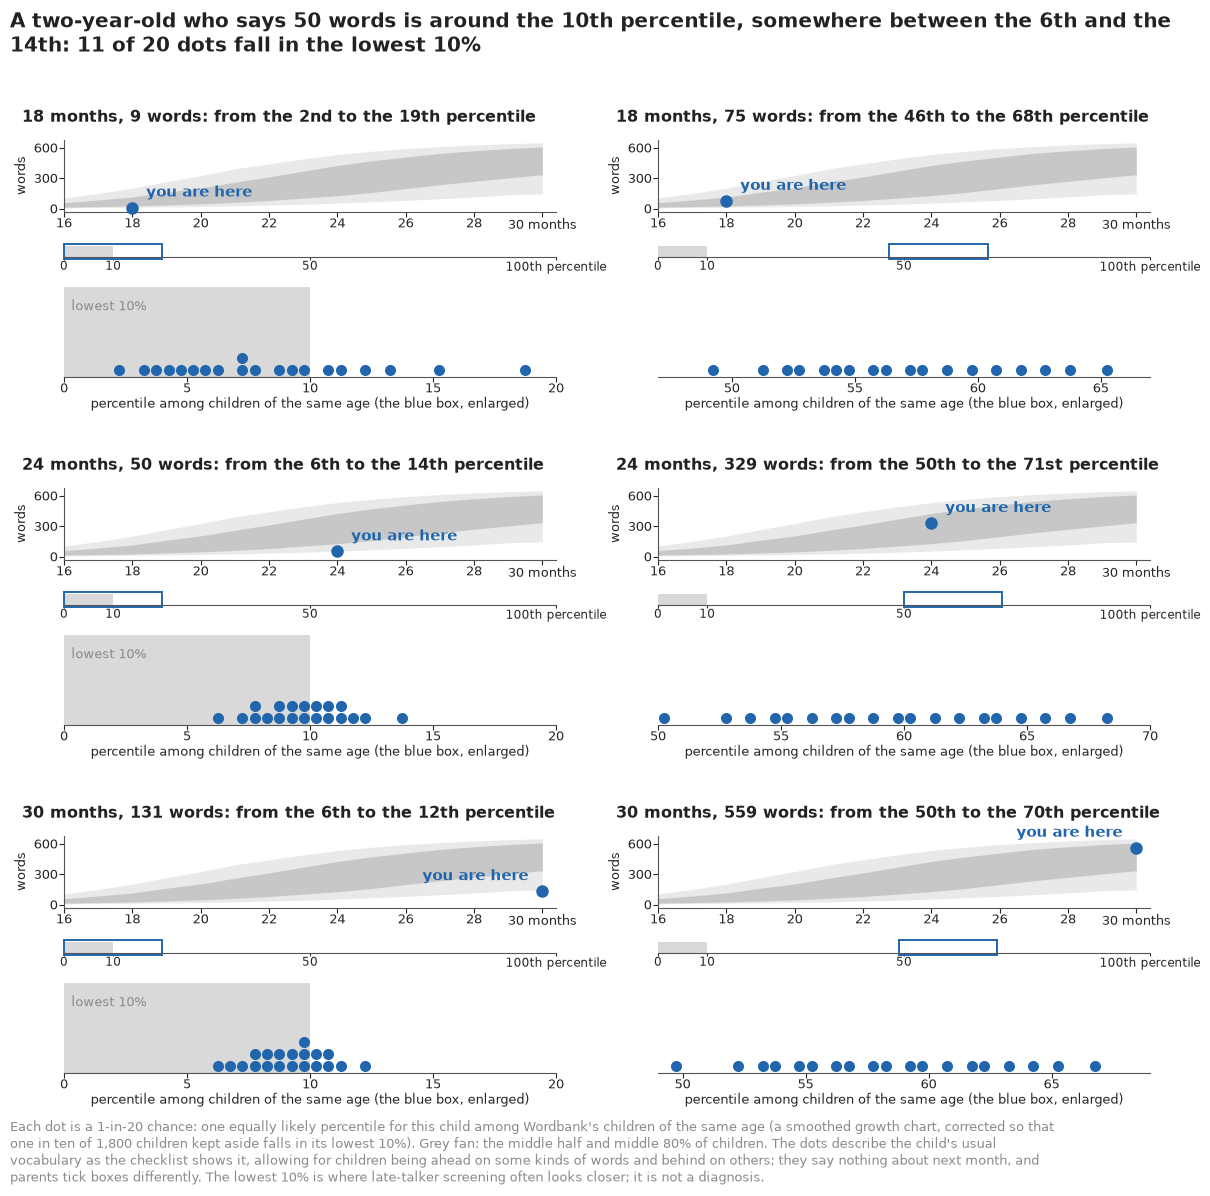

In [2]:
HOW_SURE = display(Markdown("**How sure are we.** *Filled in from the fits in part H.*"),
                   display_id=True)
HEADLINE = display(Markdown("*The headline figure is drawn in part H from the fits below and "
                            "appears here once the notebook has run.*"), display_id=True)

## The setting

Between 18 months and two years most children go through a burst of words: a toddler who said
"ball", "dog" and "uh oh" at Christmas is naming animals, food and body parts by the summer.
Parents ask the same question in every clinic and playground: *is my child on track?* Behind it
sit two more. Which words come first? And are girls really ahead of boys, and first-borns ahead
of their siblings?

The standard instrument is the MacArthur-Bates Communicative Development Inventory (CDI; Fenson et
al. 2007, *User's Guide and Technical Manual*, 2nd edition). Its Words & Sentences form, for
children of 16 to 30 months, lists 680 words in 22 sections, from animal sounds and body parts to
pronouns and connecting words, and a parent ticks the ones their child says. The manual turns the
count into a percentile for the child's age and sex. Late-talker research uses a similar line:
Rescorla's (1989, *Journal of Speech and Hearing Disorders*) shorter Language Development Survey
flags fewer than 50 words at 24 months, about a tenth of two-year-olds in a later population
screening (Rescorla & Alley 2001). **Wordbank** (Frank, Braginsky, Yurovsky & Marchman 2017,
*Journal of Child Language*; and their 2021 book *Variability and Consistency in Early Language
Learning*) pools CDI checklists from dozens of studies into one open archive; we use its 9,537
American English Words & Sentences checklists.

A checklist is a test, and the statistics of tests is **item response theory**: each word has a
difficulty and a sharpness, each child a latent ability, and the chance that a child says a word
depends on the gap between the two. The two-parameter logistic model is Birnbaum's (1968, in Lord
& Novick); De Boeck & Wilson (2004) add covariates, and Kachergis, Marchman & Frank (2022,
*Current Directions in Psychological Science*) apply IRT to the CDI. Whether an item is easier for
one group than its overall ability predicts is **differential item functioning** (DIF; Holland &
Thayer 1988, Holland & Wainer 1993), the check that exam boards run for fairness.

The model gives a parent what a raw count cannot: the age by which half of children say each word,
group differences on a scale that does not depend on which words happen to be easy, and, for one
child, a percentile that carries its own uncertainty. Two cautions run through the notebook. The
CDI is a parent's report, not a test given by a stranger, and Wordbank is a collection of research
samples, not a census of American toddlers. Part D shows where they bite.

| part | question | tool |
|---|---|---|
| A | What do 9,537 checklists look like? | raw word curves, word counts by month |
| B | What is a two-parameter item response model? | 200 simulated children, the weighted score |
| C | How hard and how sharp is each word? | marginal likelihood, adaptive quadrature, a ridge |
| D | Where do children of each age stand? | norms, a step at 28 months, cells, a held-out check |
| E | Which words come first? | age of acquisition, sections, a check per word |
| F | Do girls, boys and first-borns differ? | gaps in words, item bias with a horseshoe |
| G | Where does one child stand? | split-half check, a corrected percentile, test information |
| H | How do we explain it to everyone? | "you are here" dotplots, a word ladder, a word strip |

## A · Nine thousand checklists

The data are Wordbank's item-by-child answers, packed into one file by
`tools/build_e116_wordbank.py`: one row per checklist, one bit per word for "says it" and one for
"was on the form", plus the child's age in months, sex, birth order and the caregiver's education
where the study recorded them.

In [3]:
data.describe("e116_wordbank_ws")
RAW = np.load(data.path("e116_wordbank_ws"))
Y = np.unpackbits(RAW["produces_bits"], axis=1, count=680)       # 1 = the parent ticked "says"
ANS = np.unpackbits(RAW["answered_bits"], axis=1, count=680)     # 1 = the word was on the form
AGE, SEX, BO, EDU = (RAW[k].astype(int) for k in ("age", "sex", "birth_order", "education"))
WORDS, CATEGORY, EDU_LAB = RAW["definition"], RAW["category"], RAW["EDUCATION"]
CATS, CAT_IDX = np.unique(CATEGORY, return_inverse=True)
J = Y.shape[1]
AGES = np.arange(16, 31)
FULL = np.flatnonzero(ANS.sum(axis=1) == J)                       # every word answered
W = Y.sum(axis=1)                                                 # words said


def wid(name):
    """Index of a word on the form ('water' finds 'water (beverage)')."""
    k = np.flatnonzero(WORDS == name)
    return int(k[0]) if k.size else int(np.flatnonzero(np.char.startswith(WORDS, name + " "))[0])


n_age = np.bincount(AGE[FULL] - 16)
print(f"{len(Y):,} checklists, {len(FULL):,} with all {J} words answered; "
      f"{n_age.min()}-{n_age.max()} complete checklists per month of age")
for lab, v in (("sex", SEX), ("birth order", BO), ("caregiver education", EDU)):
    print(f"  {lab:20s} not reported on {np.mean(v[FULL] < 0):.0%}")
known = FULL[EDU[FULL] >= 0]
print("caregiver education where reported:",
      {str(EDU_LAB[k]): f"{np.mean(EDU[known] == k):.0%}" for k in range(len(EDU_LAB))})
print("words per section:", dict(zip(CATS, np.bincount(CAT_IDX))))

e116_wordbank_ws: NumPy .npz (open data.path(...) with np.load): the 9,537 checklists aged 16-30 months (the form's normed range) x 680 words. produces_bits / answered_bits are np.packbits along words (np.unpackbits(..., axis=1, count=680) gives 0/1 'says it' and 'was on the form'; 440 checklists miss 1-2 words); per checklist: data_id, age (months), sex (0 boy, 1 girl, -1 not reported), birth_order (1 first, 2+ later, -1), education (caregiver, 0 primary ... 6 graduate, labels in EDUCATION; -1), ethnicity (0 non-Hispanic, 1 Hispanic, -1); per word: item_id, definition, category (22 sections), uni_lemma. Each data_id is one administration; repeat visits of a child cannot be linked.
  source: Wordbank (Frank, Braginsky, Yurovsky & Marchman 2017, J. Child Language 44:677-694), item-by-child responses to the MacArthur-Bates CDI Words & Sentences, English (American); retrieved 2026-11-06. Licence CC BY 4.0: the build checks Wordbank's datasets table and stops unless every English (American

Of the 9,537 checklists, 9,097 have every word answered; we drop the 440 whose forms left out a
word or two, so every child faces the same 680 items, 361 to 986 children a month. Sex is missing
on 40% of checklists, birth order on 44% and caregiver education on a third. Where education was
recorded it is high: 71% of caregivers have a college degree or more, far from the American
population. The slice records neither which study a checklist came from nor whether two
checklists are the same child at two ages; both gaps come back. The simplest summaries are the
share of children who say each word at each month, and the spread of the total.

    children  10%  median  90%  share with <= 50 words
16       930    8      35  120                   0.642
18       641   10      52  217                   0.487
20       537   17      81  316                   0.339
22       454   26     147  424                   0.192
24       986   50     267  531                   0.105
26       435   80     366  584                   0.067
28       954  236     505  650                   0.018
30       786   97     489  641                   0.056


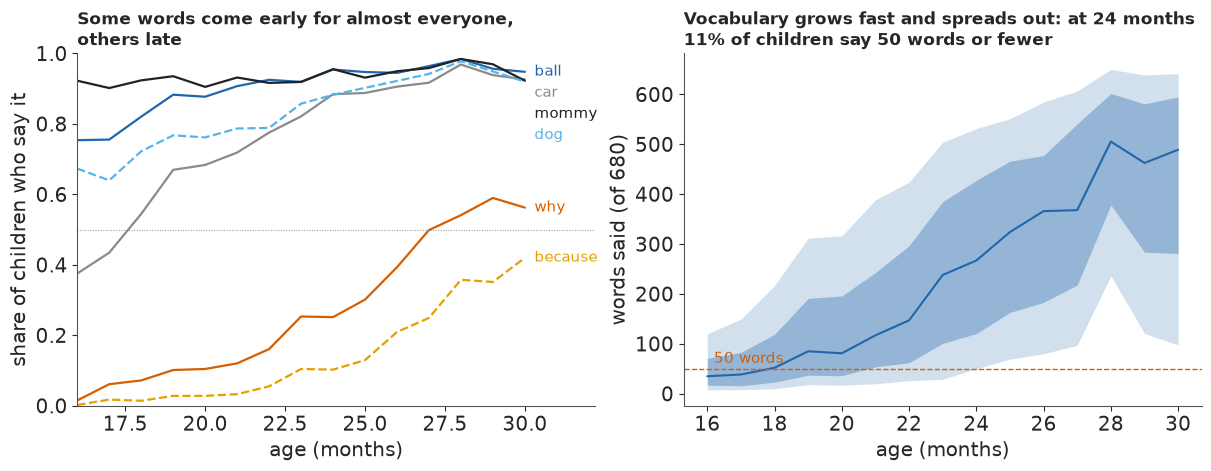

In [4]:
EMP = np.array([Y[FULL[AGE[FULL] == m]].mean(axis=0) for m in AGES])        # share saying each word
QW = np.array([np.quantile(W[FULL[AGE[FULL] == m]], [0.1, 0.25, 0.5, 0.75, 0.9]) for m in AGES])
LE50 = np.array([np.mean(W[FULL[AGE[FULL] == m]] <= 50) for m in AGES])
tab = pd.DataFrame({"children": n_age, "10%": QW[:, 0], "median": QW[:, 2], "90%": QW[:, 4],
                    "share with <= 50 words": LE50.round(3)}, index=AGES).astype({"10%": int,
                                                                                    "median": int,
                                                                                    "90%": int})
print(tab.loc[[16, 18, 20, 22, 24, 26, 28, 30]].to_string())
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.6))
lab_y = 2.0
for w_, c_, ls_ in sorted((("mommy*", INK, "-"), ("ball", HI, "-"), ("dog", "#56b4e9", "--"),
                           ("car", MUTED, "-"), ("why", LO, "-"), ("because", "#e69f00", "--")),
                          key=lambda t: -EMP[-1, wid(t[0])]):
    ax1.plot(AGES, EMP[:, wid(w_)], color=c_, lw=1.6, ls=ls_)
    lab_y = min(EMP[-1, wid(w_)], lab_y - 0.06)                   # keep the labels apart
    ax1.text(30.3, lab_y, w_.rstrip("*"), va="center", fontsize=10.5, color=c_)
ax1.axhline(0.5, color=MUTED, lw=0.7, ls=":")
ax1.set_xlim(16, 32.2)
ax1.set_ylim(0, 1)
ax1.set_xlabel("age (months)")
ax1.set_ylabel("share of children who say it")
ax1.set_title("Some words come early for almost everyone,\nothers late", loc="left", fontsize=12.5)
for (lo_, hi_), al in (((0, 4), 0.2), ((1, 3), 0.35)):
    ax2.fill_between(AGES, QW[:, lo_], QW[:, hi_], color=HI, alpha=al, lw=0)
ax2.plot(AGES, QW[:, 2], color=HI, lw=1.5)
ax2.axhline(50, color=LO, lw=1, ls="--")
ax2.text(16.2, 62, "50 words", color=LO, fontsize=10.5)
ax2.set_xlabel("age (months)")
ax2.set_ylabel("words said (of 680)")
ax2.set_title(wrap(f"Vocabulary grows fast and spreads out: at 24 months {LE50[8]:.0%} of children "
                   "say 50 words or fewer", 52), loc="left", fontsize=12.5);

In [5]:
k24 = FULL[AGE[FULL] == 24]
raw = {"girls": W[k24][SEX[k24] == 1].mean(), "boys": W[k24][SEX[k24] == 0].mean(),
       "first-born": W[k24][BO[k24] == 1].mean(), "later-born": W[k24][BO[k24] > 1].mean()}
print("raw mean words at 24 months:", {k: round(v) for k, v in raw.items()})

raw mean words at 24 months: {'girls': 305, 'boys': 251, 'first-born': 307, 'later-born': 269}


Some words are nearly universal early: "mommy" and "ball" are said by three quarters or more of
16-month-olds. "Because" is said by about one in ten two-year-olds and four in ten at 30 months.
Totals grow from a median of 35 words at 16 months to about 490 at 30, and they spread out
enormously: at 24 months the 10th percentile is 50 words and the 90th about 530. So **50 words at
two is about the 10th percentile** here (10.5% of 986 two-year-olds say 50 or fewer), roughly
where the late-talker line falls (only roughly: 50 words on the shorter LDS list mean more on the
CDI). One oddity is already visible: the median 28-month-old says 505 words, more than the median
30-month-old (489).

At 24 months girls average 305 words and boys 251, first-borns 307 and later-borns 269. Those raw
gaps mix the group difference with which studies the groups come from; raw counts treat "because"
like "ball"; and a raw percentile says nothing about how precisely one checklist places a child.
A measurement model answers all three.

## B · A tiny item response model

Write $y_{ij}=1$ if child $i$ says word $j$. The **two-parameter logistic (2PL)** model is

$$P(y_{ij}=1 \mid \theta_i) = p_j(\theta_i)
= \operatorname{logit}^{-1}\big(a_j(\theta_i - b_j)\big),$$

where $\theta_i$ is the child's ability, $b_j$ is the word's **difficulty** (the ability at which
half of children say it) and $a_j > 0$ its **sharpness** (how quickly the probability rises around
$b_j$; psychometricians say discrimination). Plotted against $\theta$, each word is an S-shaped
item characteristic curve. To see the parts move, we simulate 200 children and 20 words with known
values and fit the model with one ability per child. The prior $\theta_i \sim \mathcal N(0, 1)$
fixes where the ability scale sits and how it is stretched; without it, shifting every $\theta$
and every $b$ together, or stretching $\theta - b$ and shrinking $a$, would fit equally well.

In [6]:
sim = np.random.default_rng(1)
N_SIM, J_SIM = 200, 20
th_true = sim.normal(0, 1, N_SIM)
b_true = np.linspace(-2, 2, J_SIM) + sim.normal(0, 0.2, J_SIM)
a_true = np.exp(sim.normal(0.3, 0.35, J_SIM))
y_sim = sim.binomial(1, special.expit(a_true * (th_true[:, None] - b_true)))
with pm.Model(coords={"child": np.arange(N_SIM), "word": np.arange(J_SIM)}) as tiny:
    theta = pm.Normal("theta", 0.0, 1.0, dims="child")
    b = pm.Normal("b", 0.0, 2.0, dims="word")
    log_a = pm.Normal("log_a", 0.0, 0.5, dims="word")
    pm.Bernoulli("y", logit_p=pt.exp(log_a) * (theta[:, None] - b), observed=y_sim)
    t0 = time.time()
    idata_tiny = pm.sample(random_seed=RANDOM_SEED, progressbar=False)
TIMES["tiny"] = time.time() - t0
diagnose(idata_tiny, ["theta", "b", "log_a"])
pt_ = idata_tiny.posterior
b_hat = pt_["b"].mean(("chain", "draw")).values
a_hat = np.exp(pt_["log_a"]).mean(("chain", "draw")).values
th_sd = pt_["theta"].std(("chain", "draw")).values
print(f"recovery: corr(b) {np.corrcoef(b_hat, b_true)[0, 1]:.3f}, corr(a) "
      f"{np.corrcoef(a_hat, a_true)[0, 1]:.2f}; posterior sd of a child's ability: median "
      f"{np.median(th_sd):.2f} (the population sd is 1)")

divergences 0; tuning steps 400; tree depth counts {3: 11, 4: 3989}


  theta   r_hat max 1.006   ESS min  5715
  b       r_hat max 1.004   ESS min  2105
  log_a   r_hat max 1.003   ESS min  2180
recovery: corr(b) 0.982, corr(a) 0.88; posterior sd of a child's ability: median 0.47 (the population sd is 1)


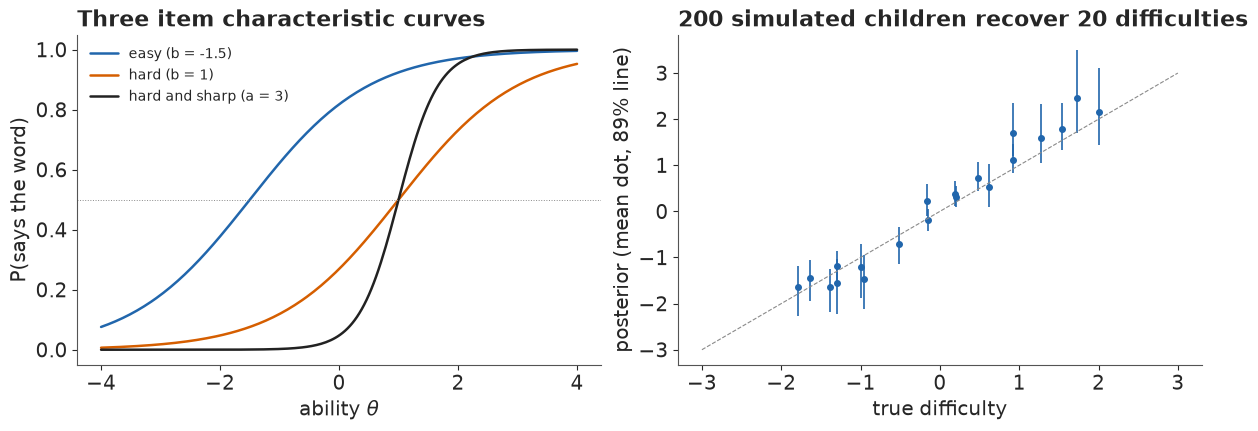

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))
tg_ = np.linspace(-4, 4, 200)
for (a_, b_, lab, c_) in ((1.0, -1.5, "easy (b = -1.5)", HI), (1.0, 1.0, "hard (b = 1)", LO),
                          (3.0, 1.0, "hard and sharp (a = 3)", INK)):
    ax1.plot(tg_, special.expit(a_ * (tg_ - b_)), color=c_, lw=1.8, label=lab)
ax1.axhline(0.5, color=MUTED, lw=0.7, ls=":")
ax1.set_xlabel(r"ability $\theta$")
ax1.set_ylabel("P(says the word)")
ax1.legend(loc="upper left", fontsize=10)
ax1.set_title("Three item characteristic curves", loc="left")
lo_b, hi_b = np.quantile(pt_["b"].values.reshape(-1, J_SIM), [0.055, 0.945], axis=0)
ax2.vlines(b_true, lo_b, hi_b, color=HI, lw=1.2)
ax2.plot(b_true, b_hat, "o", color=HI, ms=4)
ax2.plot([-3, 3], [-3, 3], color=MUTED, lw=0.8, ls="--")
ax2.set_xlabel("true difficulty")
ax2.set_ylabel("posterior (mean dot, 89% line)")
ax2.set_title("200 simulated children recover 20 difficulties", loc="left");

The sampler had no trouble (0 divergences, r_hat at most 1.006). Difficulties come back closely
(correlation 0.98 with the truth), sharpness less so (0.88), and each child's ability has a
posterior sd of about 0.47: 20 answers say little about one child. With 680 words that changes,
and so does the cost.

### The weighted score

For one child, write $\eta_j = a_j(\theta - b_j)$. Since $\log p = \eta - \log(1 + e^\eta)$ and
$\log(1-p) = -\log(1+e^\eta)$, the log-likelihood of all the child's answers is

$$\ell_i(\theta) = \sum_j \big[y_{ij}\log p_j(\theta) + (1-y_{ij})\log(1 - p_j(\theta))\big]
= \theta S_{1i} - S_{2i} + C(\theta),$$

with $S_{1i} = \sum_j y_{ij} a_j$, $S_{2i} = \sum_j y_{ij} a_j b_j$ and $C(\theta) = -\sum_j
\log(1 + e^{a_j(\theta - b_j)})$. Every child answered every word, so $C(\theta)$ is the same
function for all of them, and the 680 answers enter the likelihood through two numbers ($S_{1i}$,
a count weighted by sharpness, is the 2PL's sufficient statistic for $\theta$). Each child's
ability can then be integrated out in one dimension,

$$p(\mathbf y_i) = \int \exp\big(\theta S_{1i} - S_{2i} + C(\theta)\big)\,
\pi(\theta \mid \text{age}_i)\, d\theta,$$

which is the marginal likelihood that Bock & Aitkin (1981, *Psychometrika*) maximised with
quadrature. We check the identity on the first simulated child.

In [8]:
i_ = 0
yi = y_sim[i_]
grid_ = np.linspace(-3, 3, 7)
direct = (yi * special.log_expit(a_true * (grid_[:, None] - b_true))
          + (1 - yi) * special.log_expit(-a_true * (grid_[:, None] - b_true))).sum(axis=1)
S1_, S2_ = yi @ a_true, yi @ (a_true * b_true)
C_ = special.log_expit(-a_true * (grid_[:, None] - b_true)).sum(axis=1)
print(f"child 0: S1 = {S1_:.3f}, S2 = {S2_:.3f}; largest |direct - (theta S1 - S2 + C)| "
      "over the grid: "
      f"{np.abs(direct - (grid_ * S1_ - S2_ + C_)).max():.1e}")

child 0: S1 = 14.135, S2 = -11.665; largest |direct - (theta S1 - S2 + C)| over the grid: 2.1e-14


The two sides agree to $10^{-14}$. What changes is the work per gradient: one (children x 680) by
(680 x 2) matrix product and $C(\theta)$ on a grid, instead of a log-probability per answer and a
parameter per child.

### Failure 1: one parameter per child

The obvious approach keeps every $\theta_i$ as a parameter, as in the tiny model. On 600 real
children (408,000 answers and about 2,000 parameters) it does not finish in 25 minutes, against a
budget of six minutes for the whole notebook, so we do not run it here. Under the 2PL each child's
ability is pinned to a few hundredths of a population sd (we measure this below), while the word
parameters are learned from all children, so the sampler must move hundreds of very narrow
directions and a few broad ones together, in small steps. Integrating the abilities out removes
the narrow directions.

## C · Calibrating 680 words

The word parameters do not need every child: we calibrate on 60 random children per month, 900
in all, hold out 1,800 at random for checking, and fit the norms in part D on the other 7,297.

The calibration model, with $x = (\text{age} - 24)/6$:

$$\theta_i \sim \mathcal N\big(f(\text{age}_i),\ e^{\kappa x_i}\big), \qquad
f(16) \sim \mathcal N(-1, 2),\quad f(m+1) - f(m) \sim \text{Gamma}(2, 4),$$

$$b_j \sim \mathcal N(\mu_b[c_j],\ s_b), \qquad \log a_j \sim \mathcal N(\mu_{\log a}[c_j],\
s_{\log a}), \qquad \mu_b \sim \text{ZeroSumNormal}(2),$$

where $c_j$ is the word's section. Ability grows with age in positive monthly steps, its spread is
1 at 24 months (which fixes the scale) and may change with age through $\kappa$. Words of a
section share a typical difficulty and sharpness, so a rare word borrows from its neighbours; with
900 children answering every word the centred form mixes better (the E25 lesson). Each child's
ability is integrated out, with $C(\theta)$ on a 0.1 grid interpolated (four-point Lagrange) at
each child's own **adaptive Gauss-Hermite** nodes (Pinheiro & Bates 1995; the `nAGQ` of lme4): $K$
nodes $m_i + \sqrt 2\, s_i x_k$ centred on the child's posterior mean $m_i$ and scaled by its
posterior sd $s_i$, with weights $w_k e^{x_k^2}\sqrt 2\, s_i$. To place them we first find the
mode with a cruder integral, a common 0.1 grid.

In [9]:
rs = np.random.default_rng(RANDOM_SEED)
CAL = np.sort(np.concatenate([rs.choice(FULL[AGE[FULL] == m], 60, replace=False) for m in AGES]))
HOLD = np.sort(rs.choice(np.setdiff1d(FULL, CAL), 1800, replace=False))
FIT2 = np.setdiff1d(FULL, HOLD)
print(f"calibration sample {len(CAL)} (60 per month); norms fitted on {len(FIT2):,}; "
      f"{len(HOLD):,} held out")
y_cal = Y[CAL].astype(float)
ag_cal = AGE[CAL] - 16
COORDS = {"word": WORDS, "cat": CATS, "age": AGES}


def stage1_model(nodes=None, log_w=None, fine=None, step=0.1):
    """Marginal 2PL, each child's ability integrated out: on a common grid (fine) or own nodes."""
    with pm.Model(coords=COORDS) as m:
        f16 = pm.Normal("f16", -1.0, 2.0)
        inc = pm.Gamma("inc", alpha=2.0, beta=4.0, dims="age")
        f = pm.Deterministic("f", f16 + pt.cumsum(pt.set_subtensor(inc[0], 0.0)), dims="age")
        kappa = pm.Normal("kappa", 0.0, 0.5)
        mu, sd = f[ag_cal], pt.exp(kappa * (ag_cal - 8) / 6.0)
        mu_b = pm.ZeroSumNormal("mu_b", 2.0, dims="cat")
        s_b = pm.HalfNormal("s_b", 1.5)
        b = pm.Normal("b", mu_b[CAT_IDX], s_b, dims="word")
        mu_la = pm.Normal("mu_la", 0.0, 0.5, dims="cat")
        s_la = pm.HalfNormal("s_la", 0.5)
        la = pm.Normal("la", mu_la[CAT_IDX], s_la, dims="word")
        a = pm.Deterministic("a", pt.exp(la), dims="word")
        S12 = pt.dot(y_cal, pt.stack([a, a * b], axis=1))        # the weighted scores S1, S2
        if fine is not None:                                     # common grid, trapezoid weights
            th = fine[None, :]
            C = -pt.sum(pt.softplus(a[None, :] * (fine[:, None] - b[None, :])), axis=1)[None, :]
            lw = np.log(fine[1] - fine[0])
        else:                                                    # C on a 0.1 grid, 4-point Lagrange
            lo = np.floor(nodes.min() / step) * step - 2 * step
            cg = np.arange(lo, np.ceil(nodes.max() / step) * step + 3 * step + 1e-9, step)
            u = (nodes - lo) / step
            i0 = np.floor(u).astype(int) - 1
            t = u - (i0 + 1)
            W4 = np.stack([-t * (t - 1) * (t - 2) / 6, (t + 1) * (t - 1) * (t - 2) / 2,
                           -(t + 1) * t * (t - 2) / 2, (t + 1) * t * (t - 1) / 6], -1)
            Cg = -pt.sum(pt.softplus(a[None, :] * (cg[:, None] - b[None, :])), axis=1)
            C = pt.sum(Cg[i0[..., None] + np.arange(4)] * W4, axis=-1)
            th, lw = nodes, log_w
        z = (th - mu[:, None]) / sd[:, None]
        lp = th * S12[:, 0:1] - S12[:, 1:2] + C - 0.5 * z**2 - pt.log(sd)[:, None] + lw
        pm.Potential("lik", pt.sum(pt.logsumexp(lp, axis=1)) - len(CAL) * 0.5 * np.log(2 * np.pi))
    return m


t0 = time.time()
m_grid = stage1_model(fine=np.arange(-10, 10 + 1e-9, 0.1))
MAP = pm.find_MAP(model=m_grid, progressbar=False, maxeval=5000)
TIMES["map"] = time.time() - t0
print(f"MAP on a common 0.1 grid: {TIMES['map']:.0f} s")

calibration sample 900 (60 per month); norms fitted on 7,297; 1,800 held out


MAP on a common 0.1 grid: 14 s


With the mode's word parameters fixed, we can measure each integral against a reference on a 0.002
grid: the posterior sd of each child's ability, and the error of a common 0.1 grid and of adaptive
quadrature with 4, 8 and 12 nodes (the last two widened by 1.3, a margin for nodes placed from the
mode rather than the final fit).

In [10]:
a0, b0 = MAP["a"], MAP["b"]
mu0, sd0 = MAP["f"][ag_cal], np.exp(MAP["kappa"] * (ag_cal - 8) / 6)
FG = np.arange(-12, 12, 0.002)                                   # the reference: a 0.002 grid
C_fine = special.log_expit(-a0[None, :] * (FG[:, None] - b0[None, :])).sum(axis=1)
S1c, S2c = y_cal @ a0, y_cal @ (a0 * b0)
lpf = (FG[None, :] * S1c[:, None] - S2c[:, None] + C_fine[None, :]
       + stats.norm.logpdf(FG[None, :], mu0[:, None], sd0[:, None]))
exact = special.logsumexp(lpf, axis=1) + np.log(0.002)
w_ = np.exp(lpf - lpf.max(axis=1, keepdims=True))
w_ /= w_.sum(axis=1, keepdims=True)
m_i = w_ @ FG
s_i = np.sqrt(np.maximum(w_ @ FG**2 - m_i**2, 1e-12))
del lpf, w_
print(f"posterior sd of a child's ability: median {np.median(s_i):.3f}, 90th percentile "
      f"{np.quantile(s_i, 0.9):.3f}, largest {s_i.max():.2f}")


def loglik_at(th):
    C = special.log_expit(-a0[None, None, :] * (th[..., None] - b0[None, None, :])).sum(axis=-1)
    return th * S1c[:, None] - S2c[:, None] + C + stats.norm.logpdf(th, mu0[:, None], sd0[:, None])


rows = []
G01 = np.arange(-10, 10 + 1e-9, 0.1)
cg_ = special.log_expit(-a0[None, :] * (G01[:, None] - b0[None, :])).sum(axis=1)
lp01 = (G01[None, :] * S1c[:, None] - S2c[:, None] + cg_[None, :]
        + stats.norm.logpdf(G01[None, :], mu0[:, None], sd0[:, None]))
err = special.logsumexp(lp01, axis=1) + np.log(0.1) - exact
rows.append(("common grid, step 0.1 (201 points)", err.sum(), np.abs(err).max()))
for K, infl in ((4, 1.0), (8, 1.3), (12, 1.3)):
    x, wk = np.polynomial.hermite.hermgauss(K)
    nod = m_i[:, None] + np.sqrt(2) * infl * s_i[:, None] * x
    agh = (special.logsumexp(loglik_at(nod) + np.log(wk) + x**2, axis=1)
           + np.log(np.sqrt(2) * infl * s_i))
    rows.append((f"adaptive Gauss-Hermite, K = {K}, widened x{infl}", (agh - exact).sum(),
                 np.abs(agh - exact).max()))
print(pd.DataFrame(rows, columns=["integral", "total error (nats)", "worst child (nats)"])
      .to_string(index=False, float_format=lambda v: f"{v:+.4f}"))
print(f"(total log-likelihood {exact.sum():,.0f} nats over {len(CAL)} children)")

posterior sd of a child's ability: median 0.034, 90th percentile 0.096, largest 0.50


                                    integral  total error (nats)  worst child (nats)
          common grid, step 0.1 (201 points)            -15.5277             +0.8068
 adaptive Gauss-Hermite, K = 4, widened x1.0             +0.1710             +0.0360
 adaptive Gauss-Hermite, K = 8, widened x1.3             +0.1191             +0.0190
adaptive Gauss-Hermite, K = 12, widened x1.3             -0.0279             +0.0098
(total log-likelihood -187,723 nats over 900 children)


Under the model, one checklist pins a child's ability to a posterior sd of about 0.03 population
sds (median 0.034; 90% of children under 0.1; part G finds sections multiply this by 1.6 to 3.0,
which does not change the integrals). Only children at the floor are vague (sd up to 0.5). So a
0.1 grid, wider than most posteriors, misses needle-thin peaks: 15.5 nats off in total, nearly a
nat for the worst child. Adaptive quadrature puts its nodes on the needle: eight nodes are off by
0.12 nats over 900 children, out of about -188,000. We use 8 nodes here and 4 in part D (0.04
nats at worst for one child), plenty for 25 parameters.

### Failure 2: a scale that floats

In the marginal likelihood only $a_j(\theta - b_j)$ appears. Adding the same constant to every
difficulty and to the whole age curve $f$ moves every child's ability with it and leaves every
probability unchanged. We check this at the mode.

In [11]:
shift = 0.5
th_s = np.arange(-12, 12, 0.01)
def total_loglik(b_, mu_):
    C = special.log_expit(-a0[None, :] * (th_s[:, None] - b_[None, :])).sum(axis=1)
    S2 = y_cal @ (a0 * b_)
    lp = (th_s[None, :] * S1c[:, None] - S2[:, None] + C[None, :]
          + stats.norm.logpdf(th_s[None, :], mu_[:, None], sd0[:, None]))
    return (special.logsumexp(lp, axis=1) + np.log(0.01)).sum()


L0, L1 = total_loglik(b0, mu0), total_loglik(b0 + shift, mu0 + shift)
print(f"log-likelihood at the MAP {L0:,.4f}; with every difficulty and the age curve moved up by "
      f"{shift}: {L1:,.4f} (difference {L1 - L0:+.1e})")

log-likelihood at the MAP -187,723.1932; with every difficulty and the age curve moved up by 0.5: -187,723.1932 (difference -8.7e-11)


The log-likelihood does not change (by $10^{-10}$): the data cannot say where zero is on the
ability scale, only the priors can. Give the section means $\mu_b$ free normal priors and nothing
but those priors holds the line, so the chains drift slowly along it: when we tried it, with zero
divergences, r_hat reached 1.43 and the difficulties' effective sample size fell to 8 (a run of a
minute and a half that we do not repeat here). A **zero-sum** prior on the section means makes
the location part of the model: difficulties are measured from the average section, and the line
is gone.

Now the full calibration fit: 500 draws per chain after nutpie's 400 tuning steps.

In [12]:
x8, w8 = np.polynomial.hermite.hermgauss(8)
NODES1 = m_i[:, None] + np.sqrt(2) * 1.3 * s_i[:, None] * x8
LOGW1 = np.log(w8)[None, :] + x8**2 + np.log(np.sqrt(2) * 1.3 * s_i)[:, None]
m_stage1 = stage1_model(nodes=NODES1, log_w=LOGW1)
t0 = time.time()
with m_stage1:
    idata1 = pm.sample(draws=500, tune=400, chains=4, random_seed=RANDOM_SEED, progressbar=False)
TIMES["stage1"] = time.time() - t0
print(f"sampling {TIMES['stage1']:.0f} s")
diagnose(idata1, ["f", "kappa", "mu_b", "s_b", "mu_la", "s_la", "a", "b"])
po1 = idata1.posterior
IT = {k: po1[k].values.reshape(-1, *po1[k].shape[2:]) for k in ("a", "b", "f", "kappa", "mu_b",
                                                                   "s_b", "mu_la", "s_la")}
A_M, B_M = IT["a"].mean(axis=0), IT["b"].mean(axis=0)
print(f"between-word spread within a section: difficulty s_b {IT['s_b'].mean():.2f}, "
      f"log sharpness s_la {IT['s_la'].mean():.2f}; sharpness a ranges "
      f"{A_M.min():.2f}-{A_M.max():.2f} (median {np.median(A_M):.2f})")
LP_SD = float(idata1.sample_stats["logp"].std())
del idata1, m_grid, m_stage1
qerr = []                                      # the fixed nodes, re-checked at posterior draws
for s in np.random.default_rng(5).choice(len(IT["a"]), 3, replace=False):
    a_, b_, mu_ = IT["a"][s], IT["b"][s], IT["f"][s][ag_cal]
    sd_ = np.exp(IT["kappa"][s] * (ag_cal - 8) / 6)
    S1_, S2_ = y_cal @ a_, y_cal @ (a_ * b_)
    ref = special.logsumexp(FG[None, :] * S1_[:, None] - S2_[:, None]
                            + special.log_expit(-a_ * (FG[:, None] - b_)).sum(axis=1)[None, :]
                            + stats.norm.logpdf(FG[None, :], mu_[:, None], sd_[:, None]),
                            axis=1) + np.log(0.002)
    Cn = special.log_expit(-a_ * (NODES1[..., None] - b_)).sum(axis=-1)
    agh = special.logsumexp(NODES1 * S1_[:, None] - S2_[:, None] + Cn + LOGW1
                            + stats.norm.logpdf(NODES1, mu_[:, None], sd_[:, None]), axis=1)
    qerr.append(((agh - ref).sum(), np.abs(agh - ref).max()))
print("8 fixed nodes at three posterior draws: total error "
      + ", ".join(f"{t:+.3f}" for t, _ in qerr) + " nats; worst child "
      + ", ".join(f"{w:.3f}" for _, w in qerr))
print(f"spread of the error between these draws {np.ptp([t for t, _ in qerr]):.1f} nats; sd of the "
      f"log posterior across all draws {LP_SD:.0f} nats")

sampling 57 s
divergences 0; tuning steps 400; tree depth counts {4: 1921, 5: 79}
  f       r_hat max 1.008   ESS min   545
  kappa   r_hat max 1.004   ESS min  2530
  mu_b    r_hat max 1.006   ESS min  1488
  s_b     r_hat max 1.002   ESS min  1507
  mu_la   r_hat max 1.008   ESS min  1011
  s_la    r_hat max 1.002   ESS min  1450


  a       r_hat max 1.012   ESS min   700


  b       r_hat max 1.012   ESS min   450
between-word spread within a section: difficulty s_b 0.55, log sharpness s_la 0.21; sharpness a ranges 0.94-5.37 (median 2.96)


8 fixed nodes at three posterior draws: total error -3.481, -4.954, -5.266 nats; worst child 0.044, 0.062, 0.032
spread of the error between these draws 1.8 nats; sd of the log posterior across all draws 28 nats


The calibration is clean: 0 divergences, r_hat at most 1.012 and effective sample sizes of at
least 450, in about a minute. Within a section, difficulties spread with $s_b \approx 0.55$, half
a population sd, so a section says something about a word but far from everything; log sharpness
spreads only 0.21, so sharpness is pooled hard. Most words are sharp: $a$ runs from about 0.9 to
5.4, median 3, so a typical word goes from 20% to 80% of children over about 0.9 population sd.
The nodes were placed from the mode and held fixed, so the last lines re-check them at three
posterior draws: the error grows to 3.5-5.3 nats in total as the needles drift off the nodes.
Most of it is a common offset, which does not change the posterior; its variation between draws,
about 1.8 nats, is small against a log posterior whose sd across draws is 28 nats. Re-centring
the nodes after warm-up would shrink it.

## D · Norms from seven thousand children

The norms are the population of abilities at each age. Here we fix the words at their posterior
means and fit the population on the 7,297 children not held out. This is a **plug-in two-stage
fit**: the norms do not feed back into the words, as in a cut (Plummer 2015, *Statistics and
Computing*), but a true cut would refit the norms at each draw of the words. Instead each norm
draw is later paired with an independent draw of the words, which carries the words' noise into
the percentiles but not the norms' response to it; part G shows the norms matter little for one
child's percentile, so the shortcut costs little. With the words fixed, each child's
log-likelihood at its own four nodes is computed once in NumPy and the model has only population
parameters left.

The population is a **skew-normal** at each age (Azzalini 1985), because slow starters trail off
in a longer tail than fast ones:

$$\theta_i \sim \text{SkewNormal}\big(\mu_i,\ e^{\kappa x_i},\ \alpha_0 + \alpha_1 x_i\big),
\qquad \mu_i = f(\text{age}_i) + \boldsymbol\beta^\top \mathbf z_i + \beta_{\text{edu}}\,
\text{educ}_i,$$

with $\mathbf z_i$ indicators for girl, later-born and three "not reported" flags (sex, birth
order, education), and education scored in steps of two levels from College. We start with the
monotone age curve of the calibration.

In [13]:
y2 = Y[FIT2].astype(float)
ag2 = AGE[FIT2] - 16


def design(ix):
    """[girl, sex n/r, later-born, birth order n/r, education n/r] (n/r: not reported), educ."""
    girl, sexna, later = SEX[ix] == 1, SEX[ix] < 0, BO[ix] > 1
    bona, eduna = BO[ix] < 0, EDU[ix] < 0
    educ = np.where(eduna, 0, EDU[ix] - 4) / 2.0          # 0 at College, +1 Graduate, -1 Secondary
    return np.c_[girl, sexna, later, bona, eduna].astype(float), educ


X2, educ2 = design(FIT2)
TGF = np.arange(-12, 9, 0.005)                                   # fine grid for C(theta) tables
C_M = special.log_expit(-A_M[None, :] * (TGF[:, None] - B_M[None, :])).sum(axis=1)
S1m, S2m = y2 @ A_M, y2 @ (A_M * B_M)
fg = np.arange(-12, 8, 0.02)
mu_p = IT["f"].mean(axis=0)[ag2]
sd_p = np.exp(IT["kappa"].mean() * (ag2 - 8) / 6)
lp = (fg[None, :] * S1m[:, None] - S2m[:, None] + np.interp(fg, TGF, C_M)[None, :]
      + stats.norm.logpdf(fg[None, :], mu_p[:, None], sd_p[:, None]))
w_ = np.exp(lp - lp.max(axis=1, keepdims=True))
w_ /= w_.sum(axis=1, keepdims=True)
m2 = w_ @ fg
s2 = np.sqrt(np.maximum(w_ @ fg**2 - m2**2, 1e-12))
s2 = np.maximum(s2, 0.01)
del lp, w_
x4, w4 = np.polynomial.hermite.hermgauss(4)
NODES2 = m2[:, None] + np.sqrt(2) * s2[:, None] * x4
BASE2 = (NODES2 * S1m[:, None] - S2m[:, None] + np.interp(NODES2, TGF, C_M)
         + np.log(w4) + x4**2 + np.log(np.sqrt(2) * s2)[:, None])
BASE2 -= BASE2.max()                                              # a constant: irrelevant

XA = (AGES - 24) / 6.0
POLY = np.c_[np.ones(AGES.size), XA, XA**2]                      # smooth growth: a quadratic
M_PERP = np.linalg.qr(POLY, mode="complete")[0][:, 3:]          # month deviations orthogonal to it


def norms_model(curve):
    """Population of abilities: skew-normal by age, covariate shifts; `curve` sets the age curve."""
    with pm.Model(coords={"age": AGES, "dev": np.arange(M_PERP.shape[1]),
                          "cov": ["girl", "sex n/r", "later-born", "order n/r", "educ n/r"]}) as m:
        if curve == "monotone":
            f16 = pm.Normal("f16", -1.0, 2.0)
            inc = pm.Gamma("inc", alpha=2.0, beta=4.0, dims="age")
            f = pm.Deterministic("f", f16 + pt.cumsum(pt.set_subtensor(inc[0], 0.0)), dims="age")
            f_full = f
        else:
            c = pm.Normal("c", np.array([0.0, 1.0, 0.0]), np.array([1.5, 1.0, 0.5]), shape=3)
            f = pm.Deterministic("f", pt.dot(POLY, c), dims="age")
            s_u = pm.HalfNormal("s_u", 0.3)
            zu = pm.Normal("zu", 0.0, s_u, dims="dev")
            u = pm.Deterministic("u", pt.dot(M_PERP, zu), dims="age")
            f_full = pm.Deterministic("f_full", f + u, dims="age")
        kappa = pm.Normal("kappa", 0.0, 0.5)
        alpha = pm.Normal("alpha", 0.0, 3.0, shape=2)
        beta = pm.Normal("beta", 0.0, 0.5, dims="cov")
        b_edu = pm.Normal("b_edu", 0.0, 0.5)
        mu = f_full[ag2] + pt.dot(X2, beta) + b_edu * educ2
        scale = pt.exp(kappa * (ag2 - 8) / 6.0)
        al = alpha[0] + alpha[1] * (ag2 - 8) / 6.0
        z = (NODES2 - mu[:, None]) / scale[:, None]
        log_prior = (-0.5 * z**2 - pt.log(scale)[:, None]
                     + pt.log(0.5 * pt.erfc(-pt.maximum(al[:, None] * z, -30.0) / np.sqrt(2.0))))
        pm.Potential("lik", pt.sum(pt.logsumexp(BASE2 + log_prior, axis=1)))
    return m


t0 = time.time()
with norms_model("monotone"):
    idata2m = pm.sample(draws=500, tune=400, chains=4, random_seed=RANDOM_SEED, progressbar=False)
TIMES["stage2_monotone"] = time.time() - t0
print(f"{len(FIT2):,} children, 25 parameters; sampling {TIMES['stage2_monotone']:.0f} s")
diagnose(idata2m, ["f", "kappa", "alpha", "beta", "b_edu"])
F_MONO = idata2m.posterior["f"].values.reshape(-1, AGES.size)
print("age curve f by month:", dict(zip(AGES.tolist(), F_MONO.mean(axis=0).round(2).tolist())))
print("increase from one month to the next:", np.diff(F_MONO.mean(axis=0)).round(2))
print("raw median words by month:", dict(zip(AGES.tolist(), QW[:, 2].astype(int).tolist())))


def age_of_acquisition(P):
    """First age at which P >= 0.5 (linear interpolation); -inf before 16 months, +inf after 30."""
    above = P >= 0.5
    i = above.argmax(axis=-2)
    i0 = np.clip(i - 1, 0, None)
    p0 = np.take_along_axis(P, i0[..., None, :], -2)[..., 0, :]
    p1 = np.take_along_axis(P, i[..., None, :], -2)[..., 0, :]
    out = AGES[i0] + (0.5 - p0) / (p1 - p0)
    out = np.where(i == 0, -np.inf, out)
    return np.where(~above.any(axis=-2), np.inf, out)


pm_ = idata2m.posterior                                # share saying each word, monotone curve
km_, alm_ = float(pm_["kappa"].mean()), pm_["alpha"].mean(("chain", "draw")).values
pat_, patw_ = np.unique(np.c_[X2 @ pm_["beta"].mean(("chain", "draw")).values
                              + float(pm_["b_edu"].mean()) * educ2], return_counts=True)
PJ_fg = special.expit(A_M[None, :] * (fg[:, None] - B_M[None, :]))
P_MONO = np.array([(patw_[:, None] / patw_.sum() * np.exp(sn_logpdf(
    fg[None, :], F_MONO.mean(axis=0)[k] + pat_[:, None], np.exp(km_ * (m - 24) / 6),
    alm_[0] + alm_[1] * (m - 24) / 6))).sum(axis=0) * 0.02 @ PJ_fg for k, m in enumerate(AGES)])
AOA_MONO = age_of_acquisition(P_MONO)
print("monotone curve: words whose age of acquisition falls in [26, 27) "
      f"{np.sum((AOA_MONO >= 26) & (AOA_MONO < 27))}, [27, 28) "
      f"{np.sum((AOA_MONO >= 27) & (AOA_MONO < 28))}, [28, 30] "
      f"{np.sum((AOA_MONO >= 28) & (AOA_MONO <= 30))}")
del idata2m, PJ_fg

7,297 children, 25 parameters; sampling 63 s
divergences 0; tuning steps 400; tree depth counts {4: 87, 5: 1462, 6: 451}
  f       r_hat max 1.004   ESS min   717
  kappa   r_hat max 1.011   ESS min  1042
  alpha   r_hat max 1.004   ESS min   786
  beta    r_hat max 1.003   ESS min  1623
  b_edu   r_hat max 1.000   ESS min  2719
age curve f by month: {16: -1.63, 17: -1.42, 18: -1.12, 19: -0.81, 20: -0.66, 21: -0.43, 22: -0.22, 23: 0.11, 24: 0.27, 25: 0.44, 26: 0.63, 27: 0.86, 28: 1.19, 29: 1.22, 30: 1.27}
increase from one month to the next: [0.21 0.3  0.31 0.15 0.22 0.21 0.33 0.16 0.17 0.19 0.23 0.33 0.03 0.04]
raw median words by month: {16: 35, 17: 38, 18: 52, 19: 85, 20: 81, 21: 117, 22: 147, 23: 238, 24: 267, 25: 324, 26: 366, 27: 368, 28: 505, 29: 462, 30: 489}
monotone curve: words whose age of acquisition falls in [26, 27) 86, [27, 28) 117, [28, 30] 0


### Failure 3: a growth curve that learned the datasets

The fit is healthy (0 divergences, r_hat at most 1.011), and wrong in a way no diagnostic shows:
the age curve climbs by 0.15-0.33 a month, jumps by 0.33 to 28 months and then nearly stops (0.03
and 0.04). Children do not stop learning words at 28 months. The raw medians tell the story:
Wordbank's 28-month-olds (505 words) are ahead of its 29- and 30-month-olds (462 and 489),
probably because different studies contribute different months. A monotone curve can only follow
them up and then wait, and everything built on it inherits the step: under this curve 117 words
reach "half of children say it" in the month before 28 and none between 28 and 30 (the smooth
curve below gives about 60 and 77).

Without a study identifier we cannot model studies, but we can separate a smooth growth curve, a
quadratic in $x$, from month deviations $u$ **orthogonal to the quadratic**, so the two cannot
trade off:

$$f_{\text{full}}(m) = c_0 + c_1 x_m + c_2 x_m^2 + u_m, \qquad \mathbf u = M\mathbf z, \quad
z_k \sim \mathcal N(0, s_u),$$

where the 12 columns of $M$ are an orthonormal basis of everything the quadratic cannot express
over the 15 months. The deviations describe *these* children in *this* month, so we use them to
predict Wordbank children of a given month; the norms, ages of acquisition and percentiles use the
smooth curve.

### Prior predictive check

The priors live on the ability scale, which nobody can picture, so we push them through to words:
population parameters from their priors, an ability for a child of each age with covariates from
a random checklist, and its expected word count from the calibrated words.

In [14]:
pr = np.random.default_rng(6)
ND, NC = 1000, 400                                  # prior draws x children per draw and month
c_pr = pr.normal([0.0, 1.0, 0.0], [1.5, 1.0, 0.5], (ND, 3))
u_pr = (pr.normal(0, 1, (ND, M_PERP.shape[1])) * np.abs(pr.normal(0, 0.3, ND))[:, None]) @ M_PERP.T
k_pr, a_pr = pr.normal(0, 0.5, ND), pr.normal(0, 3, (ND, 2))
be_pr, bed_pr = pr.normal(0, 0.5, (ND, 5)), pr.normal(0, 0.5, ND)
TGP = np.arange(-15, 15, 0.01)
EW_PRIOR = special.expit(A_M * (TGP[:, None] - B_M)).sum(axis=1)   # expected words at ability
rows = []
for m in (16, 24, 30):
    x = (m - 24) / 6
    Xp, ep = design(pr.choice(FIT2, ND * NC))
    off = ((Xp.reshape(ND, NC, 5) * be_pr[:, None, :]).sum(axis=-1)
           + bed_pr[:, None] * ep.reshape(ND, NC))
    th = stats.skewnorm.rvs((a_pr[:, 0] + a_pr[:, 1] * x)[:, None],
                            (c_pr @ POLY[m - 16] + u_pr[:, m - 16])[:, None] + off,
                            np.exp(k_pr * x)[:, None], random_state=pr)
    q10, q50, q90 = np.quantile(np.interp(th, TGP, EW_PRIOR), [0.1, 0.5, 0.9], axis=1)
    lo_, md_, hi_ = np.quantile(q50, [0.05, 0.5, 0.95])
    rows.append(dict(month=m, prior_median_words_5pct=lo_, prior_median_words_50pct=md_,
                     prior_median_words_95pct=hi_,
                     prior_spread_10_90_median=np.median(q90 - q10),
                     data_median=QW[m - 16, 2], data_spread_10_90=QW[m - 16, 4] - QW[m - 16, 0]))
print(pd.DataFrame(rows).round(0).astype(int).to_string(index=False))
del th, Xp, ep, off

 month  prior_median_words_5pct  prior_median_words_50pct  prior_median_words_95pct  prior_spread_10_90_median  data_median  data_spread_10_90
    16                        0                        41                       679                        136           35                112
    24                        4                       357                       679                        324          267                482
    30                        7                       620                       680                        195          489                544


The priors are weak on the scale that matters: across prior draws the median child of any age
says anything from almost no words to nearly all 680 (5% and 95% points 0-7 and 679-680). They
carry growth, from a prior median of about 40 words at 16 months to about 620 at 30, and a spread
within an age (140-320 words between the 10th and 90th percentile child) of the same order as the
data's 110-540. The answer is left to the 7,297 children.

In [15]:
t0 = time.time()
with norms_model("smooth"):
    idata2 = pm.sample(draws=500, tune=400, chains=4, random_seed=RANDOM_SEED, progressbar=False)
TIMES["stage2"] = time.time() - t0
print(f"sampling {TIMES['stage2']:.0f} s")
diagnose(idata2, ["c", "s_u", "u", "f", "kappa", "alpha", "beta", "b_edu"])
po2 = idata2.posterior
NM = {k: po2[k].values.reshape(-1, *po2[k].shape[2:])
      for k in ("f", "f_full", "u", "s_u", "kappa", "alpha", "beta", "b_edu")}
print("month deviations u:", dict(zip(AGES.tolist(), NM["u"].mean(axis=0).round(2).tolist())),
      f" s_u {NM['s_u'].mean():.2f}")
print(az.summary(idata2, var_names=["c", "kappa", "alpha", "beta", "b_edu"], round_to=3)
      [["mean", "sd", "eti89_lb", "eti89_ub", "r_hat"]].to_string())
del idata2

sampling 24 s
divergences 0; tuning steps 400; tree depth counts {3: 298, 4: 1687, 5: 15}
  c       r_hat max 1.004   ESS min   498
  s_u     r_hat max 1.001   ESS min  2506
  u       r_hat max 1.012   ESS min  2358
  f       r_hat max 1.004   ESS min   479
  kappa   r_hat max 1.003   ESS min   550
  alpha   r_hat max 1.003   ESS min   472
  beta    r_hat max 1.005   ESS min   992
  b_edu   r_hat max 1.001   ESS min  2611
month deviations u: {16: 0.03, 17: -0.03, 18: 0.0, 19: 0.05, 20: -0.03, 21: -0.04, 22: -0.05, 23: 0.04, 24: -0.0, 25: -0.03, 26: -0.03, 27: 0.01, 28: 0.2, 29: -0.01, 30: -0.11}  s_u 0.09
                   mean     sd  eti89_lb  eti89_ub  r_hat
c[0]              0.276  0.028     0.231     0.321  1.004
c[1]              1.208  0.054     1.115     1.291  1.003
c[2]             -0.153  0.026    -0.193    -0.109  1.002
kappa             0.245  0.024     0.201     0.278  1.003
alpha[0]         -0.975  0.038    -1.035    -0.914  1.003
alpha[1]         -0.630  0.121    -0.80

The smooth model samples faster (under 30 s; 0 divergences, r_hat at most about 1.01). Its month
deviations are within ±0.05 except at 28 months (+0.20) and 30 months (-0.11). In units of the
24-month scale (the population sd at 24 months is about 0.83 of them), the curve gains about 0.2 a
month at 24 months and slows with age; the spread grows with age ($\kappa \approx 0.25$), and the
skew is to the left ($\alpha_0 \approx -1$): a long tail of children who start slowly. Girls sit
0.19 above boys (about a month of growth) and later-borns 0.14 below first-borns; each two steps
of caregiver education adds 0.12. The "not reported" flags are as large as any of these (-0.41 for
birth order, +0.40 for education): the studies that did not ask are probably different samples,
the same problem as at 28 months.

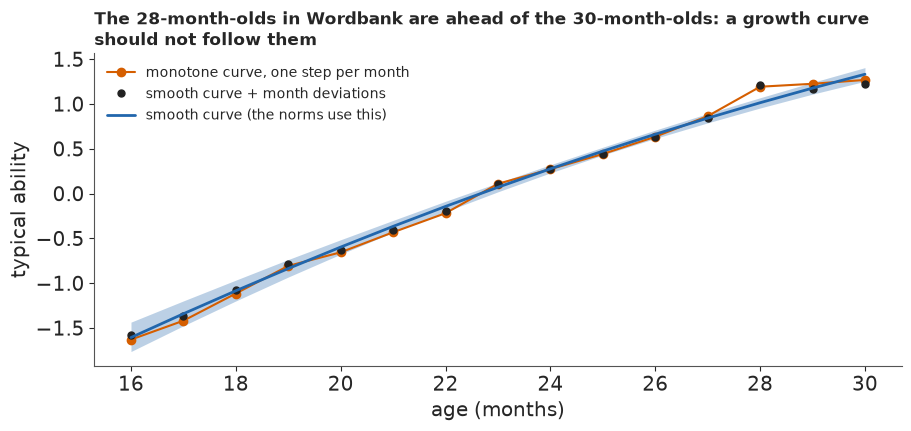

In [16]:
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(AGES, F_MONO.mean(axis=0), "o-", color=LO, lw=1.5,
        label="monotone curve, one step per month")
ax.plot(AGES, NM["f_full"].mean(axis=0), "o", color=INK, ms=5,
        label="smooth curve + month deviations")
lo_f, hi_f = np.quantile(NM["f"], [0.055, 0.945], axis=0)
ax.fill_between(AGES, lo_f, hi_f, color=HI, alpha=0.3, lw=0)
ax.plot(AGES, NM["f"].mean(axis=0), color=HI, lw=2, label="smooth curve (the norms use this)")
ax.set_xlabel("age (months)")
ax.set_ylabel("typical ability")
ax.legend(fontsize=10, loc="upper left")
ax.set_title(wrap("The 28-month-olds in Wordbank are ahead of the 30-month-olds: a growth curve "
                  "should not follow them", 80), loc="left", fontsize=12.5);

### Failure 4: counting by cells

Aggregating into cells is the obvious shortcut: word x month x sex, each cell a binomial count
with probability $\int p_j(\theta)\,\pi(\theta)\,d\theta$. It is fast and sounds exact. But a
cell's counts for "dog" and "cat" come from the same children: the binomial likelihood treats each
child's 680 answers as 680 different children. It is a **composite likelihood** (Varin, Reid &
Firth 2011), right on average and far too sure. We compare the two likelihoods for the girls'
shift $\gamma$ on the 4,355 children of known sex, with everything else fixed at the norms'
posterior means: the age curve, spread and skew, and each child's other covariates (in the cells,
the cell's mix of them).

In [17]:
sexk = FIT2[SEX[FIT2] >= 0]
yk = Y[sexk].astype(float)
gk = (SEX[sexk] == 1).astype(float)
agk = AGE[sexk] - 16
f_m, k_m, al_m = NM["f_full"].mean(axis=0), NM["kappa"].mean(), NM["alpha"].mean(axis=0)
Xk, ek = design(sexk)
offk = Xk[:, 2:] @ NM["beta"].mean(axis=0)[2:] + NM["b_edu"].mean() * ek   # other covariates, fixed
sck = np.exp(k_m * (agk - 8) / 6)
alk = al_m[0] + al_m[1] * (agk - 8) / 6
LLk = (fg[None, :] * (yk @ A_M)[:, None] - (yk @ (A_M * B_M))[:, None]
       + np.interp(fg, TGF, C_M)[None, :])


def exact_ll(gam):
    return special.logsumexp(LLk + sn_logpdf(fg[None, :], (f_m[agk] + offk + gam * gk)[:, None],
                                             sck[:, None], alk[:, None]), axis=1).sum()


cells = agk * 2 + gk.astype(int)
uc, inv = np.unique(cells, return_inverse=True)
n_cell = np.bincount(inv)
y_cell = np.zeros((uc.size, J))
np.add.at(y_cell, inv, yk)
CELL_OFF = [np.unique(offk[inv == k], return_counts=True) for k in range(uc.size)]
PJ = special.expit(A_M[None, :] * (fg[:, None] - B_M[None, :]))


def cell_ll(gam):
    tot = 0.0
    for k, c in enumerate(uc):
        a_, g_ = divmod(c, 2)
        o_, n_o = CELL_OFF[k]                      # the cell's mix of the other covariates
        dens = (n_o[:, None] / n_o.sum() * np.exp(sn_logpdf(
            fg[None, :], f_m[a_] + o_[:, None] + gam * g_, np.exp(k_m * (a_ - 8) / 6),
            al_m[0] + al_m[1] * (a_ - 8) / 6))).sum(axis=0) * 0.02
        P = np.clip(dens @ PJ, 1e-12, 1 - 1e-12)
        tot += np.sum(y_cell[k] * np.log(P) + (n_cell[k] - y_cell[k]) * np.log1p(-P))
    return tot


def curvature_sd(fn, lo=0.0, hi=0.4, n=21, h=0.002):
    gs = np.linspace(lo, hi, n)
    v = np.array([fn(g) for g in gs])
    k = int(np.clip(np.argmax(v), 1, n - 2))
    d = gs[1] - gs[0]
    top = gs[k] + 0.5 * d * (v[k - 1] - v[k + 1]) / (v[k - 1] - 2 * v[k] + v[k + 1])
    c = (fn(top + h) - 2 * fn(top) + fn(top - h)) / h**2
    return gs, v, top, 1 / np.sqrt(-c)


t0 = time.time()
CURV = {name: curvature_sd(fn) for name, fn in (("each child once", exact_ll),
                                                 ("counting by cells", cell_ll))}
TIMES["cells"] = time.time() - t0
for name, (_, _, top, sd_) in CURV.items():
    print(f"{name:18s}: girl shift at its best {top:.3f}, width (sd from the curvature) {sd_:.4f}")
RATIO = CURV["each child once"][3] / CURV["counting by cells"][3]
print(f"{len(sexk):,} children with sex reported, {uc.size} cells x {J} words; "
      f"the cell likelihood is {RATIO:.0f} times too sure")
del LLk

each child once   : girl shift at its best 0.192, width (sd from the curvature) 0.0178
counting by cells : girl shift at its best 0.203, width (sd from the curvature) 0.0013
4,355 children with sex reported, 30 cells x 680 words; the cell likelihood is 14 times too sure


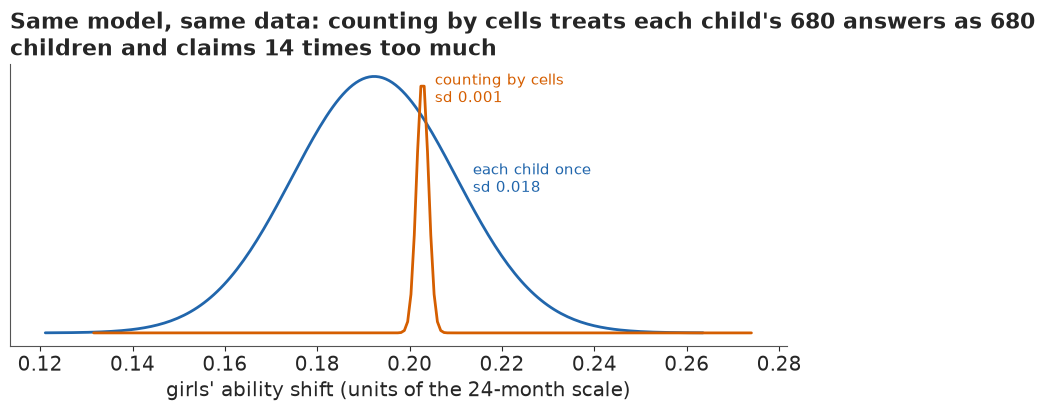

In [18]:
fig, ax = plt.subplots(figsize=(8, 4))
for (name, (gs, v, top, sd_)), c_ in zip(CURV.items(), (HI, LO)):
    sd1 = CURV["each child once"][3]
    gg = np.linspace(top - 4 * sd1, top + 4 * sd1, 200)
    ax.plot(gg, np.exp(-0.5 * ((gg - top) / sd_) ** 2), color=c_, lw=2)
    ax.text(top + (1.2 if c_ == HI else 0.15) * sd1, 0.9 if c_ == LO else 0.55,
            f"{name}\nsd {sd_:.3f}", color=c_, fontsize=10.5)
ax.set_xlabel("girls' ability shift (units of the 24-month scale)")
ax.set_yticks([])
ax.set_title(wrap("Same model, same data: counting by cells treats each child's 680 answers as "
                  f"680 children and claims {RATIO:.0f} times too much", 80), loc="left");

Both likelihoods peak in nearly the same place, 0.19 and 0.20, the norms' girl effect, but the
width from the cell likelihood is 0.0013 against 0.0178 from the per-child marginal: **14 times
too sure**. A posterior from it would sample perfectly and report a fourteenth of the real
uncertainty. A sandwich adjustment could correct it; here the exact per-child likelihood costs
little more, thanks to the weighted score.

### Checking the norms on children they have not seen

Do the norms describe children outside the fit? For each of the 1,800 held-out children and each
of 200 paired draws (word parameters from part C, population from this part), we draw an ability
from the population for the child's month and covariates, then a word count given that ability (a
normal approximation to the sum of 680 Bernoullis). Where the child's real count falls among its
predictions is its **probability integral transform**: if the model is right, a tenth of children
fall in each tenth.

In [19]:
TH = np.arange(0, IT["a"].shape[0], 10)                         # 200 paired draws
DR = len(TH)
a_d, b_d = IT["a"][TH], IT["b"][TH]
f_d, ff_d, k_d, al_d, be_d, ed_d = (NM[k][TH] for k in ("f", "f_full", "kappa", "alpha", "beta",
                                                          "b_edu"))
TG = np.arange(-8, 6, 0.02)
EW = np.empty((DR, TG.size))
VW = np.empty((DR, TG.size))
PJD = np.empty((DR, TG.size, J), dtype=np.float32)
for s in range(DR):
    p_ = special.expit(a_d[s][None, :] * (TG[:, None] - b_d[s][None, :]))
    PJD[s] = p_
    EW[s], VW[s] = p_.sum(axis=1), (p_ * (1 - p_)).sum(axis=1)


def norm_params(X, educ, age, s, full=False):
    """Draw s of the population at `age`: smooth curve (the norms), or with the month deviation."""
    mu = (ff_d if full else f_d)[s][age - 16] + X @ be_d[s] + ed_d[s] * educ
    scale = np.exp(k_d[s] * (age - 24) / 6.0) * np.ones_like(mu)
    al = (al_d[s, 0] + al_d[s, 1] * (age - 24) / 6.0) * np.ones_like(mu)
    return mu, scale, al


Xh, eh = design(HOLD)
pit = np.zeros(len(HOLD))
prng = np.random.default_rng(2)
for s in range(DR):
    mu, scale, al = norm_params(Xh, eh, AGE[HOLD], s, full=True)
    t = stats.skewnorm.rvs(al, mu, scale, random_state=prng)
    w_rep = prng.normal(np.interp(t, TG, EW[s]), np.sqrt(np.interp(t, TG, VW[s])))
    pit += (w_rep < W[HOLD]) / DR
dec = np.histogram(pit, bins=10, range=(0, 1))[0] / len(HOLD)
print("held-out children, share in each tenth of their predictive distribution "
      "(0.10 each if right):")
print(" ", dec.round(3))
below = np.array([np.mean(pit[AGE[HOLD] == m] < 0.1) for m in AGES])
nh = np.array([np.sum(AGE[HOLD] == m) for m in AGES])
print("share below the predicted 10th percentile, by month:",
      dict(zip(AGES.tolist(), below.round(3).tolist())))
print(f"overall {np.mean(pit < 0.1):.3f} below the 10th, {np.mean(pit > 0.9):.3f} above the 90th")


def month_spread(share, p0, df):
    """Chi-square of monthly shares about p0, and the spread 15 months give by chance alone."""
    chi2 = np.sum((share * nh - nh * p0) ** 2 / (nh * p0 * (1 - p0)))
    sim_ = np.random.default_rng(9).binomial(nh, p0, (4000, nh.size)) / nh
    lo_s, hi_s = np.median(sim_.min(axis=1)), np.median(sim_.max(axis=1))
    return (f"chi-square {chi2:.1f} on {df} df, p = {stats.chi2.sf(chi2, df):.2f}; with "
            f"{nh.min()}-{nh.max()} children a month, a perfectly calibrated model gives a typical "
            f"lowest month of {lo_s:.1%} and highest of {hi_s:.1%}")


print("months against 10%:", month_spread(below, 0.1, 15))

held-out children, share in each tenth of their predictive distribution (0.10 each if right):
  [0.089 0.087 0.091 0.111 0.109 0.122 0.116 0.123 0.082 0.063]
share below the predicted 10th percentile, by month: {16: 0.082, 17: 0.061, 18: 0.107, 19: 0.078, 20: 0.114, 21: 0.141, 22: 0.126, 23: 0.18, 24: 0.052, 25: 0.088, 26: 0.079, 27: 0.091, 28: 0.071, 29: 0.087, 30: 0.063}
overall 0.089 below the 10th, 0.072 above the 90th
months against 10%: chi-square 21.2 on 15 df, p = 0.13; with 55-194 children a month, a perfectly calibrated model gives a typical lowest month of 5.5% and highest of 15.0%


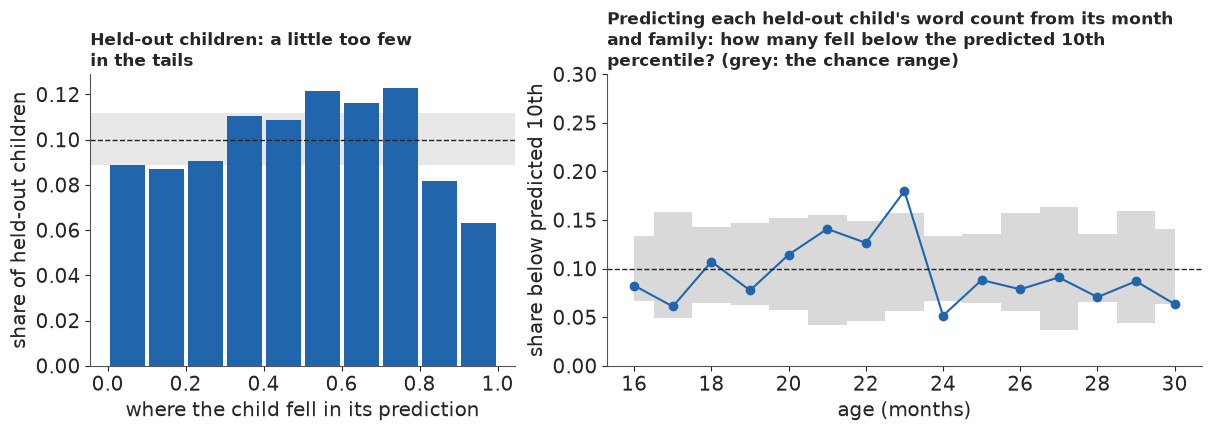

In [20]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2), width_ratios=[1, 1.4])
ax1.bar(np.arange(10) * 0.1 + 0.05, dec, width=0.09, color=HI, zorder=2)
ax1.axhline(0.1, color=INK, lw=1, ls="--")
lo_, hi_ = stats.binom.ppf([0.055, 0.945], len(HOLD), 0.1) / len(HOLD)
ax1.axhspan(lo_, hi_, color=LIGHT, alpha=0.6, lw=0, zorder=0)
ax1.set_xlabel("where the child fell in its prediction")
ax1.set_ylabel("share of held-out children")
ax1.set_title("Held-out children: a little too few\nin the tails", loc="left", fontsize=12.5)
ax2.axhspan(0, 1, color="white")
lo_m = stats.binom.ppf(0.055, nh, 0.1) / nh
hi_m = stats.binom.ppf(0.945, nh, 0.1) / nh
ax2.fill_between(AGES, lo_m, hi_m, color=LIGHT, step="mid", lw=0)
ax2.plot(AGES, below, "o-", color=HI)
ax2.axhline(0.1, color=INK, lw=1, ls="--")
ax2.set_xlabel("age (months)")
ax2.set_ylabel("share below predicted 10th")
ax2.set_ylim(0, 0.3)
ax2.set_title(wrap("Predicting each held-out child's word count from its month and family: how "
                   "many fell below the predicted 10th percentile? (grey: the chance range)", 58),
              loc="left", fontsize=12.5);

The predictions are a little too wide: the tenths hold about 0.06 to 0.125 of the children, with
about 9% in the bottom tenth and 6% in the top, so the model's tails are too heavy. By month the
share below the predicted 10th percentile runs from 5% (24 months) to 18% (23), which looks
alarming until we ask what chance gives: with 55 to 194 children a month, a perfectly calibrated
model would typically show a lowest month near 5.5% and a highest near 15% (chi-square 21 on 15
df, p = 0.13). The signal is in the tails overall, not in any one month. Two limits hold for this
and every later held-out check: held-out children come from the same studies as the fitted ones,
so a study mix that differs in spread or shape is invisible; and some held-out checklists may be
children whose checklist at another age is in the fit. Part G repeats the check for the
published percentiles.

## E · Which words come first

The **age of acquisition** of a word is the age at which half of children say it. For each paired
draw we compute, at each month,

$$P_j(m) = \int p_j(\theta)\, \pi_m(\theta)\, d\theta,$$

the share of children who would say word $j$, where $\pi_m$ is the smooth population at month $m$
averaged over a fixed reference mix of covariates (all 9,097 complete checklists), and interpolate
the age at which $P_j$ crosses one half; words past it at 16 months are "before 16", words not
there by 30 "after 30". With each month's actual mix instead, $P_j(m)$ can be compared with the
raw shares.

In [21]:
Xa, ea = design(FULL)
PATS, PAT_W = np.unique(np.c_[Xa, ea], axis=0, return_counts=True)   # the reference population
PAT_W = PAT_W / PAT_W.sum()
AGE_W = np.array([np.unique(np.c_[Xa, ea][AGE[FULL] == m], axis=0, return_counts=True)[1]
                  for m in AGES], dtype=object)                       # actual mix, by month
pat_index = [np.unique(np.c_[Xa, ea][AGE[FULL] == m], axis=0) for m in AGES]


def pop_density(s, age, pats, wts):
    mu, scale, al = norm_params(pats[:, :5], pats[:, 5], age, s)
    return (wts[:, None] * np.exp(sn_logpdf(TG[None, :], mu[:, None], scale[:, None],
                                            al[:, None]))).sum(axis=0) * 0.02


DENS = np.empty((DR, AGES.size, TG.size))
P_REF = np.empty((DR, AGES.size, J))
P_MIX = np.zeros((AGES.size, J))
for s in range(DR):
    for i, m in enumerate(AGES):
        DENS[s, i] = pop_density(s, m, PATS, PAT_W)
        if s % 4 == 0:
            wmix = AGE_W[i] / AGE_W[i].sum()
            P_MIX[i] += pop_density(s, m, pat_index[i], wmix) @ PJD[s] / (DR / 4)
    P_REF[s] = DENS[s] @ PJD[s]
CDF = np.cumsum(DENS, axis=2)
CDF /= CDF[:, :, -1:]
AOA = age_of_acquisition(P_REF)                                  # (draws, words)
AOA_EMP = age_of_acquisition(EMP)
fin = np.isfinite(AOA).all(axis=0)
early = (AOA == -np.inf).mean(axis=0) > 0.5
late = (AOA == np.inf).mean(axis=0) > 0.5
AOA_MED = np.median(AOA, axis=0)
ok = fin & np.isfinite(AOA_EMP)
print(f"age of acquisition inside 16-30 months in every draw: {fin.sum()} words; said by half "
      f"before 16 months: {early.sum()}; not until after 30: {late.sum()}")
print(f"model against the raw curves ({ok.sum()} words): correlation "
      f"{np.corrcoef(AOA_MED[ok], AOA_EMP[ok])[0, 1]:.3f}, mean absolute difference "
      f"{np.abs(AOA_MED[ok] - AOA_EMP[ok]).mean():.2f} months")
wd = np.quantile(AOA[:, fin], 0.945, axis=0) - np.quantile(AOA[:, fin], 0.055, axis=0)
print(f"89% interval width: median {np.median(wd):.2f} months, widest {wd.max():.2f}")
print("smooth curve: words whose age of acquisition falls in [26, 27) "
      f"{np.sum((AOA_MED >= 26) & (AOA_MED < 27))}, [27, 28) "
      f"{np.sum((AOA_MED >= 27) & (AOA_MED < 28))}, [28, 30] "
      f"{np.sum((AOA_MED >= 28) & (AOA_MED <= 30))}")
print("before 16 months:", ", ".join(w.rstrip("*") for w in WORDS[early]))
o = np.argsort(np.where(fin, AOA_MED, 99))
print("earliest inside the window:",
      ", ".join(f"{WORDS[j].rstrip('*')} {AOA_MED[j]:.1f}" for j in o[:10]))
print("latest inside the window:",
      ", ".join(f"{WORDS[j]} {AOA_MED[j]:.1f}" for j in o[fin[o]][-6:]))
print("near the 16-month edge:", ", ".join(
    f"{w_} median {AOA_MED[wid(w_)]:.1f}, before 16 in {np.mean(AOA[:, wid(w_)] < 16):.0%} of draws"
    for w_ in ("book", "banana")))
print(f"model share saying each word, by month, against the data (each month's own mix): mean "
      f"absolute difference {np.abs(P_MIX - EMP).mean():.3f}, "
      f"largest {np.abs(P_MIX - EMP).max():.2f}")

age of acquisition inside 16-30 months in every draw: 495 words; said by half before 16 months: 10; not until after 30: 125
model against the raw curves (494 words): correlation 0.985, mean absolute difference 0.37 months
89% interval width: median 0.83 months, widest 1.77
smooth curve: words whose age of acquisition falls in [26, 27) 62, [27, 28) 60, [28, 30] 77
before 16 months: moo, uh oh, woof woof, dog, ball, daddy, mommy, bye, hi, no
earliest inside the window: car 17.6, eye 17.7, ouch 17.8, yes 17.8, grandma 18.0, quack quack 18.0, nose 18.0, bird 18.1, thank you 18.2, cat 18.2
latest inside the window: write 28.7, cover 28.7, farm 28.8, yard 28.9, new 28.9, to 28.9
near the 16-month edge: book median 16.8, before 16 in 0% of draws, banana median 16.9, before 16 in 0% of draws
model share saying each word, by month, against the data (each month's own mix): mean absolute difference 0.027, largest 0.21


Ten words are said by half of children before 16 months: moo, uh oh, woof woof, dog, ball, daddy,
mommy, bye, hi and no. About 495 cross one half inside the window in every draw, and about 125 not
before 30 months. The model's ages agree with the raw curves (correlation 0.985, mean difference
about 0.4 months) and are precise (median 89% interval 0.8 months): the real story is the
variation *between children*. Book and banana just miss the 16-month edge (about 16.8 and 16.9
months); car, eye, ouch and yes follow at 17.6-17.8. Month by month, the model's share saying a
word differs from the raw share by 0.027 on average, 0.21 at most.

median age of acquisition by section (15 = before 16, 31 = after 30):
  sounds 17.4; body parts 22.0; games routines 23.0; animals 23.2; vehicles 23.4; toys 24.8; food drink 24.8; household 25.3; clothing 25.4; outside 25.6; furniture rooms 25.8; action words 26.0; descriptive words 26.3; people 27.3; places 28.3; locations 29.0; question words 29.6; connecting words 31.0; helping verbs 31.0; pronouns 31.0; quantifiers 31.0; time words 31.0
section difficulty mu_b (89%), two lowest and two highest of all 22: sounds -1.36 [-1.59, -1.11]; games routines -0.68 [-0.86, -0.50]; helping verbs +0.58 [+0.39, +0.77]; connecting words +0.99 [+0.66, +1.31]


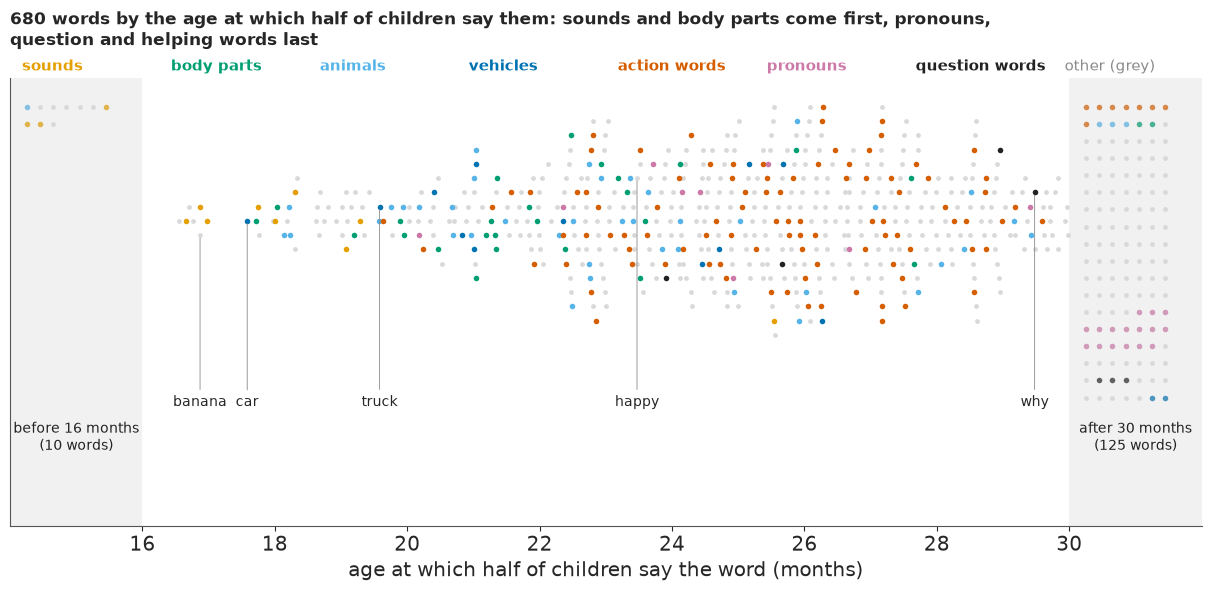

In [22]:
CAT_LAB = {c: c.replace("_", " ") for c in CATS}
cat_aoa = {c: np.median(np.clip(AOA[:, CAT_IDX == k], 15, 31)) for k, c in enumerate(CATS)}
cat_order = sorted(CATS, key=lambda c: cat_aoa[c])
print("median age of acquisition by section (15 = before 16, 31 = after 30):")
print("  " + "; ".join(f"{CAT_LAB[c]} {cat_aoa[c]:.1f}" for c in cat_order))
mub = IT["mu_b"]
ob = np.argsort(np.median(mub, axis=0))
print("section difficulty mu_b (89%), two lowest and two highest of all 22:", "; ".join(
    f"{CAT_LAB[CATS[k]]} {np.median(mub[:, k]):+.2f} [{np.quantile(mub[:, k], 0.055):+.2f}, "
    f"{np.quantile(mub[:, k], 0.945):+.2f}]" for k in (*ob[:2], *ob[-2:])))


def swarm_y(x, width=0.18, step=0.05):
    """Simple beeswarm: within each x-bin, stack points alternately above and below the line."""
    y = np.zeros_like(x)
    bins = np.floor(x / width)
    for b_ in np.unique(bins):
        k = np.flatnonzero(bins == b_)
        k = k[np.argsort(x[k])]
        y[k] = [step * ((j + 1) // 2) * (1 if j % 2 else -1) for j in range(len(k))]
    return y


show = {"sounds": "#e69f00", "body_parts": "#009e73", "animals": "#56b4e9", "vehicles": "#0072b2",
        "action_words": "#d55e00", "pronouns": "#cc79a7", "question_words": INK}
xs, ys = AOA_MED.copy(), np.zeros(J)
mid = np.isfinite(AOA_MED)
ys[mid] = swarm_y(xs[mid])
for grp, x_lo in ((AOA_MED == -np.inf, 14.25), (AOA_MED == np.inf, 30.25)):   # censored: a block
    k = np.flatnonzero(grp)
    k = k[np.argsort(CAT_IDX[k])]
    ncol = 7
    xs[k] = x_lo + 0.2 * (np.arange(k.size) % ncol)
    ys[k] = ys[mid].max() - 0.06 * (np.arange(k.size) // ncol)
fig, ax = plt.subplots(figsize=(12, 5.8))
grey = ~np.isin(CATEGORY, list(show))
ax.scatter(xs[grey], ys[grey], s=12, color=LIGHT, lw=0)
for c, col in show.items():
    k = CATEGORY == c
    ax.scatter(xs[k], ys[k], s=16, color=col, lw=0)
    ax.text(0.01 + 0.125 * list(show).index(c), 1.01, CAT_LAB[c], color=col, fontsize=10.5,
            transform=ax.transAxes, ha="left", va="bottom", weight="bold")
ax.text(0.01 + 0.125 * len(show), 1.01, "other (grey)", va="bottom", color=MUTED, fontsize=10.5,
        transform=ax.transAxes, ha="left")
for w_ in ("banana", "car", "truck", "happy", "why"):
    j = wid(w_)
    ax.annotate(w_, (xs[j], ys[j]), xytext=(xs[j], ys[mid].min() - 0.25), fontsize=10, ha="center",
                arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.6))
ax.axvspan(14, 16, color=LIGHT, alpha=0.35, lw=0)
ax.axvspan(30, 32, color=LIGHT, alpha=0.35, lw=0)
ax.text(15, ys.min() - 0.08, f"before 16 months\n({early.sum()} words)", ha="center", va="top",
        fontsize=10, color=INK)
ax.text(31, ys.min() - 0.08, f"after 30 months\n({late.sum()} words)", ha="center", va="top",
        fontsize=10, color=INK)
ax.set_xlim(14, 32)
ax.set_ylim(ys.min() - 0.45, ys.max() + 0.1)
ax.set_yticks([])
ax.set_xticks(range(16, 31, 2))
ax.set_xlabel("age at which half of children say the word (months)")
ax.set_title(wrap("680 words by the age at which half of children say them: sounds and body parts "
                  "come first, pronouns, question and helping words last", 100), loc="left",
             fontsize=12.5, pad=24);

Sounds come first (median 17.4 months), then body parts (22), games and routines, animals and
vehicles (about 23); toys, food, household words and clothing at about 25; action and descriptive
words at about 26; places, locations and question words at 28-30; and five sections, connecting
words, helping verbs, pronouns, quantifiers and time words, mostly after 30. The section means
$\mu_b$ tell the same story on the ability scale, from -1.36 for sounds to +0.99 for connecting
words. The four words the model fits worst, by their largest monthly miss, show where it fails.

worst-fitting words: ['money', 'soda/pop', 'clown', 'pretzel']


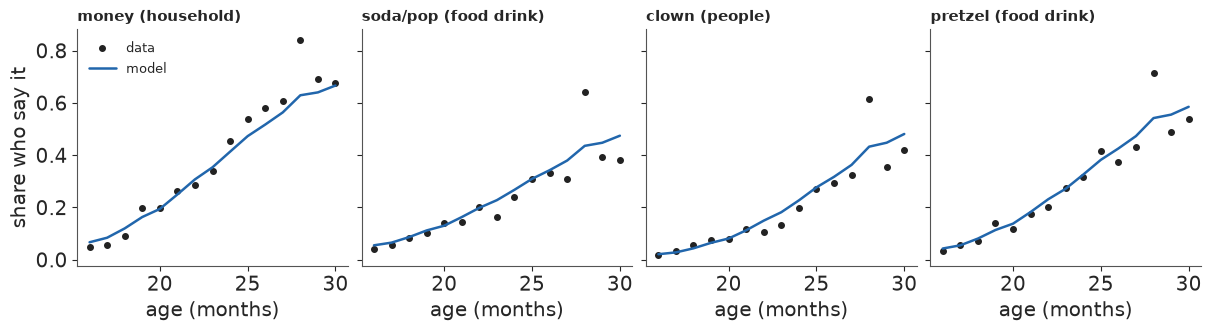

In [23]:
bad = np.argsort(-np.abs(P_MIX - EMP).max(axis=0))[:4]
fig, axs = plt.subplots(1, 4, figsize=(12, 3.2), sharey=True)
for ax, j in zip(axs, bad):
    ax.plot(AGES, EMP[:, j], "o", color=INK, ms=4, label="data")
    ax.plot(AGES, P_MIX[:, j], color=HI, lw=1.8, label="model")
    ax.set_title(f"{WORDS[j]} ({CAT_LAB[CATS[CAT_IDX[j]]]})", loc="left", fontsize=11)
    ax.set_xlabel("age (months)")
axs[0].set_ylabel("share who say it")
axs[0].legend(fontsize=9.5)
print("worst-fitting words:", [str(WORDS[j]) for j in bad])

All four (money, soda/pop, clown, pretzel) jump above the curve at 28 months, the month whose
children are ahead, by up to 0.21: the study differences again, word by word. Elsewhere the curves
follow the data closely.

## F · Girls, boys, first-borns

How much do groups differ, in words? For each draw we compute the expected words in the reference
population with everyone set to girls and then to boys (or first- and later-born, or graduate and
secondary-educated caregivers): the gap between two otherwise identical populations.

In [24]:
def mean_words(age, s, set_cols):
    """Expected words at `age` in the reference population with some covariates forced."""
    P = PATS.copy()
    for c, v in set_cols.items():
        P[:, c] = v
    return pop_density(s, age, P, PAT_W) @ EW[s]


GAPS = {}
for name, age, one, two in (
        ("girls - boys, 18 months", 18, {0: 1, 1: 0}, {0: 0, 1: 0}),
        ("girls - boys, 24 months", 24, {0: 1, 1: 0}, {0: 0, 1: 0}),
        ("girls - boys, 30 months", 30, {0: 1, 1: 0}, {0: 0, 1: 0}),
        ("first-born - later-born, 24 months", 24, {2: 0, 3: 0}, {2: 1, 3: 0}),
        ("graduate - secondary caregiver, 24 months", 24, {4: 0, 5: 1.0}, {4: 0, 5: -1.0})):
    GAPS[name] = np.array([mean_words(age, s, one) - mean_words(age, s, two) for s in range(DR)])
for name, g in GAPS.items():
    lo_, md, hi_ = np.quantile(g, [0.055, 0.5, 0.945])
    print(f"{name:42s} {md:4.0f} words (89%: {lo_:.0f} to {hi_:.0f}), "
          f"P(> 0) {pub.fmt_pct(np.mean(g > 0))}")
print(f"raw differences at 24 months: girls - boys {raw['girls'] - raw['boys']:.0f}, "
      f"first - later {raw['first-born'] - raw['later-born']:.0f}")

girls - boys, 18 months                      25 words (89%: 20 to 30), P(> 0) >99%
girls - boys, 24 months                      43 words (89%: 35 to 52), P(> 0) >99%
girls - boys, 30 months                      37 words (89%: 29 to 44), P(> 0) >99%
first-born - later-born, 24 months           31 words (89%: 23 to 39), P(> 0) >99%
graduate - secondary caregiver, 24 months    53 words (89%: 40 to 64), P(> 0) >99%
raw differences at 24 months: girls - boys 54, first - later 38


At 24 months girls say about 43 more words than boys (89%: about 35 to 52), 25 more at 18 months
and about 37 more at 30. First-borns say about 31 more than later-borns (about 23 to 39), and
children of a graduate about 53 more than children of a caregiver with secondary education (40 to
64). Each is positive in more than 99% of draws. The raw gaps at 24 months were larger (54 and
38), since the raw groups also differ in their other covariates and studies. Out of about 270
words these are real but modest gaps, small next to the spread between children (the middle 80%
of two-year-olds say 50 to 530 words). The intervals ignore that children from one study share
its quirks, so they are too narrow, by an amount the slice cannot tell us.

### Is a word fair? Item bias in two steps

A word shows **differential item functioning** if girls and boys *of the same overall ability* say
it at different rates:

$$\operatorname{logit} P(y_{ij} = 1) = a_j\big(\theta_i - b_j - \delta_j\,\text{girl}_i\big),$$

so $\delta_j < 0$ means the word comes earlier for girls than their vocabulary predicts. Most
$\delta_j$ should be near 0: a **regularised horseshoe** (Carvalho, Polson & Scott 2010; Piironen
& Vehtari 2017). Inside the full model that takes six to ten minutes, so, since one checklist pins
a child's ability to within a tenth or so, we use two steps, in the spirit of Mantel-Haenszel
matching on the score (Holland & Thayer 1988). First, each child's ability is its posterior mean
from all 680 answers, and each word gets its own $b_j$ and $\delta_j$ by Newton's method, with a
standard error. Second, the 680 raw shifts are shrunk with the horseshoe, $\hat\delta_j \sim
\mathcal N(\delta_j, \text{se}_j)$. The standard errors treat the step-one abilities as known,
each word's sharpness as fixed and the words as independent given ability, which part G shows they
are not, so they are too small and the flags below are optimistic for the borderline words. The
step-one abilities also assume the words are fair (the "purification" problem), but the shifts
point both ways and largely cancel.

In [25]:
sexall = FULL[SEX[FULL] >= 0]
yd = Y[sexall].astype(float)
gd = (SEX[sexall] == 1).astype(float)
Xd, edd = design(sexall)
mu_d = (NM["f_full"].mean(axis=0)[AGE[sexall] - 16] + Xd @ NM["beta"].mean(axis=0)
        + NM["b_edu"].mean() * edd)
sc_d = np.exp(NM["kappa"].mean() * (AGE[sexall] - 24) / 6)
al_dd = al_m[0] + al_m[1] * (AGE[sexall] - 24) / 6
fgd = np.arange(-10, 7, 0.01)
lp = (fgd[None, :] * (yd @ A_M)[:, None] - (yd @ (A_M * B_M))[:, None]
      + np.interp(fgd, TGF, C_M)[None, :] + sn_logpdf(fgd[None, :], mu_d[:, None], sc_d[:, None],
                                                       al_dd[:, None]))
w_ = np.exp(lp - lp.max(axis=1, keepdims=True))
TH_HAT = (w_ @ fgd) / w_.sum(axis=1)
del lp, w_
t0 = time.time()
Bv, Dv = B_M.copy(), np.zeros(J)
for it in range(30):                     # per word: logit = a_j (theta - b_j - delta_j girl)
    pr = special.expit(A_M[None, :] * (TH_HAT[:, None] - Bv[None, :] - Dv[None, :] * gd[:, None]))
    r = yd - pr
    wgt = pr * (1 - pr) * A_M[None, :] ** 2
    gb, gdl = -(A_M[None, :] * r).sum(axis=0), -(A_M[None, :] * r * gd[:, None]).sum(axis=0)
    Hbb, Hbd = wgt.sum(axis=0), (wgt * gd[:, None]).sum(axis=0)
    det = Hbb * Hbd - Hbd**2
    Bv += (Hbd * gb - Hbd * gdl) / det
    Dv += (-Hbd * gb + Hbb * gdl) / det
SE_D = np.sqrt(Hbb / det)
del pr, r, wgt
print(f"{len(sexall):,} children; step 1 (680 two-parameter fits) {time.time() - t0:.1f} s; "
      f"largest score after Newton {np.abs(gdl).max():.1e}; raw shifts: sd {Dv.std():.3f}, "
      f"median standard error {np.median(SE_D):.3f}")
sec_mean = np.bincount(CAT_IDX, Dv) / np.bincount(CAT_IDX)
between = np.sum((sec_mean[CAT_IDX] - Dv.mean()) ** 2) / np.sum((Dv - Dv.mean()) ** 2)
print(f"share of the shifts' variance between sections {between:.2f} "
      f"(about {(len(CATS) - 1) / (J - 1):.2f} if sections did not matter)")
with pm.Model(coords={"word": WORDS}) as dif:
    tau = pm.HalfCauchy("tau", 0.05)
    lam = pm.HalfCauchy("lam", 1.0, dims="word")
    c2 = pm.InverseGamma("c2", 2.0, 2.0 * 0.5**2)
    lam_t = pt.sqrt(c2 * lam**2 / (c2 + tau**2 * lam**2))
    z = pm.Normal("z", 0.0, 1.0, dims="word")
    delta = pm.Deterministic("delta", tau * lam_t * z, dims="word")
    pm.Normal("delta_hat", delta, SE_D, observed=Dv, dims="word")
    t0 = time.time()
    idata_dif = pm.sample(chains=4, target_accept=0.95, random_seed=RANDOM_SEED, progressbar=False)
TIMES["dif"] = time.time() - t0
print(f"step 2 (horseshoe over 680 shifts) {TIMES['dif']:.0f} s")
diagnose(idata_dif, ["delta", "tau", "c2"])
DELTA = idata_dif.posterior["delta"].values.reshape(-1, J)
P_BIG = (np.abs(DELTA) > 0.3).mean(axis=0)
SLOPE24 = (NM["f"][:, 9] - NM["f"][:, 7]).mean() / 2      # ability gained per month at 24 months
FLAG = np.flatnonzero(P_BIG > 0.9)
FLAG = FLAG[np.argsort(np.median(DELTA[:, FLAG], axis=0))]
print(f"tau {np.median(idata_dif.posterior['tau']):.3f}; ability grows {SLOPE24:.2f} a month at 24 "
      f"months; {len(FLAG)} words with P(|shift| > 0.3) > 0.9:")
for j in FLAG:
    dm = np.median(DELTA[:, j])
    print(f"  {WORDS[j]:12s} {CAT_LAB[CATS[CAT_IDX[j]]]:13s} shift {dm:+.2f} (raw {Dv[j]:+.2f} "
          f"+- {SE_D[j]:.2f}) = about {abs(dm) / SLOPE24:.1f} months earlier for "
          f"{'boys' if dm > 0 else 'girls'}")
del idata_dif

5,436 children; step 1 (680 two-parameter fits) 1.8 s; largest score after Newton 2.1e-13; raw shifts: sd 0.143, median standard error 0.030
share of the shifts' variance between sections 0.16 (about 0.03 if sections did not matter)


step 2 (horseshoe over 680 shifts) 6 s
divergences 0; tuning steps 400; tree depth counts {7: 4000}


  delta   r_hat max 1.006   ESS min  1716
  tau     r_hat max 1.003   ESS min  1266
  c2      r_hat max 1.009   ESS min   555
tau 0.043; ability grows 0.20 a month at 24 months; 18 words with P(|shift| > 0.3) > 0.9:
  vagina*      body parts    shift -1.29 (raw -1.30 +- 0.06) = about 6.4 months earlier for girls
  tights       clothing      shift -0.96 (raw -0.97 +- 0.05) = about 4.7 months earlier for girls
  dress (object) clothing      shift -0.79 (raw -0.79 +- 0.03) = about 3.9 months earlier for girls
  doll         toys          shift -0.69 (raw -0.70 +- 0.04) = about 3.4 months earlier for girls
  pretty       descriptive words shift -0.41 (raw -0.41 +- 0.03) = about 2.0 months earlier for girls
  necklace     clothing      shift -0.39 (raw -0.39 +- 0.03) = about 1.9 months earlier for girls
  fireman      people        shift +0.36 (raw +0.36 +- 0.03) = about 1.8 months earlier for boys
  motorcycle   vehicles      shift +0.36 (raw +0.36 +- 0.03) = about 1.8 months earlier for b

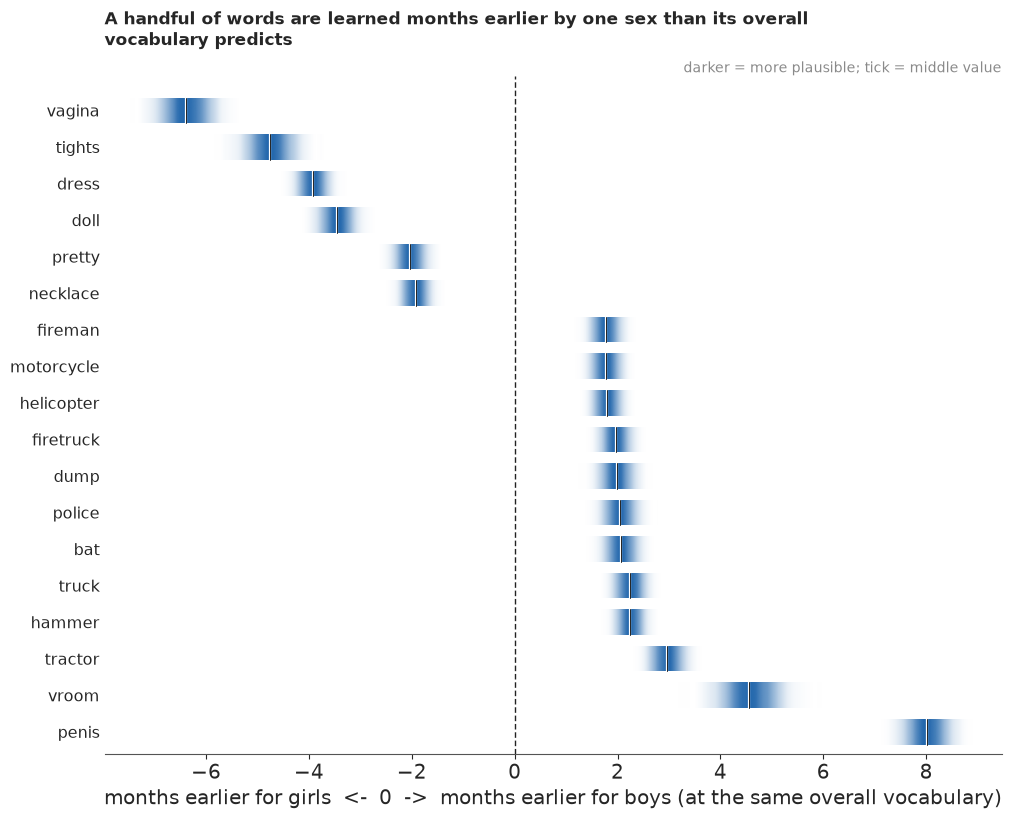

In [26]:
fig, ax = plt.subplots(figsize=(10, 0.36 * len(FLAG) + 1.6))
pub.gradient_intervals(ax, [DELTA[:, j] / SLOPE24 for j in FLAG],
                       [str(WORDS[j]).rstrip("*").replace(" (object)", "") for j in FLAG],
                       ref=0, xlabel="months earlier for girls  <-  0  ->  months earlier for boys "
                       "(at the same overall vocabulary)")
ax.set_title(wrap("A handful of words are learned months earlier by one sex than its overall "
                  "vocabulary predicts", 80), loc="left", fontsize=12.5, pad=22);

The raw shifts spread with an sd of 0.14 while their standard errors are about 0.03, so many words
carry small shifts and a few large ones: not the sparse world a horseshoe is built for, so it
shrinks the small shifts too hard, but it flags the large ones. Its global scale settles at 0.043
(0 divergences, r_hat at most about 1.01, under 10 s). We call a word biased if a shift of more
than 0.3 has posterior probability above 0.9, about a month and a half of growth at 24 months.
Eighteen words qualify. Earlier for girls: vagina, tights, dress, doll, pretty and necklace.
Earlier for boys: penis, vroom, tractor, truck, hammer, bat, police, dump, firetruck, helicopter,
motorcycle and fireman. The largest shifts are 6-8 months (the two anatomical words); tights,
vroom, dress and doll are about 3.4-4.7, tractor about 3, the other vehicles and tools about 2.
These are the toys, clothes and bodies of girls and boys, not a difference in ability, and the
horseshoe barely moves them (vagina -1.30 raw, -1.29 shrunk). They cover 18 of 680 words and point
both ways, so the total count is barely affected.

## G · One child at a time

A parent's question is about one child: given this checklist, where does my child stand among
children of the same age? The answer carries two kinds of uncertainty: **measurement** (what one
checklist says about one child) and the **norms** (what 7,297 children say about the population).

### Failure 5: words that hang together

Measurement is the larger part, and it rests on an untested assumption: given ability, the 680
answers are independent. If a child who loves trucks knows the whole vehicles page, answers in a
section move together and the model overcounts its information, as with the cells, now inside
each child. The DIF step already hinted at it: many words carry small group shifts, and 16% of the
shifts' variance lies between sections, against about 3% if sections did not matter.

A direct check is a **split-half test**: estimate each held-out child's ability from each half of
the form and compare the difference with its standard error. If the model is right, $z =
(\hat\theta_A - \hat\theta_B)/\sqrt{\text{se}_A^2 + \text{se}_B^2}$ has sd 1. We split by whole
sections (alternate sections in order of difficulty) and at random within each section, leaving
out children below 30 or above 650 words, where the prior and the ceiling dominate a half-form.

In [27]:
Xh_, eh_ = design(HOLD)
mu_h = (NM["f"].mean(axis=0)[AGE[HOLD] - 16] + Xh_ @ NM["beta"].mean(axis=0)
        + NM["b_edu"].mean() * eh_)
sc_h = np.exp(NM["kappa"].mean() * (AGE[HOLD] - 24) / 6)
prior_h = sn_logpdf(TGF[None, :], mu_h[:, None], sc_h[:, None],
                    (al_m[0] + al_m[1] * (AGE[HOLD] - 24) / 6)[:, None])
yh = Y[HOLD].astype(float)


def half_estimate(mask):
    """Posterior mean and sd of each held-out child's ability from the words in `mask` only."""
    C = special.log_expit(-A_M[mask] * (TGF[:, None] - B_M[mask])).sum(axis=1)
    lp = (TGF[None, :] * (yh[:, mask] @ A_M[mask])[:, None]
          - (yh[:, mask] @ (A_M * B_M)[mask])[:, None] + C[None, :] + prior_h)
    w = np.exp(lp - lp.max(axis=1, keepdims=True))
    w /= w.sum(axis=1, keepdims=True)
    m = w @ TGF
    return m, np.sqrt(np.maximum(w @ TGF**2 - m**2, 1e-12))


sec_order = np.argsort([B_M[CAT_IDX == k].mean() for k in range(len(CATS))])
SPLITS = {"by whole sections": np.isin(CAT_IDX, sec_order[::2])}
wrng = np.random.default_rng(7)
within = np.zeros(J, bool)
for k in range(len(CATS)):
    idx = np.flatnonzero(CAT_IDX == k)
    within[wrng.permutation(idx)[: idx.size // 2]] = True
SPLITS["at random within sections"] = within
mid_h = (W[HOLD] >= 30) & (W[HOLD] <= 650)
BANDS = np.array([30, 100, 300, 500, 651])                  # words said
SD_Z = {}
for name, mask in SPLITS.items():
    (mA, sA), (mB, sB) = half_estimate(mask), half_estimate(~mask)
    z = ((mA - mB) / np.sqrt(sA**2 + sB**2))[mid_h]
    band = np.digitize(W[HOLD][mid_h], BANDS) - 1
    SD_Z[name] = np.array([z[band == k].std() for k in range(4)])
    print(f"{name:26s} {mask.sum()}/{(~mask).sum()} words: sd of z {z.std():.2f} (1 if the words "
          f"were independent); by words said 30-100/100-300/300-500/500-650: "
          + "/".join(f"{v:.2f}" for v in SD_Z[name]))
R_BAND = SD_Z["by whole sections"] / SD_Z["at random within sections"]   # the control sets the null


def r_ld(words):
    """Inflation of the measurement sd for a child who says `words` (bands; ends extended)."""
    return R_BAND[np.clip(np.digitize(words, BANDS) - 1, 0, 3)]


print(f"{mid_h.sum():,} held-out children; inflation R (sections / within) by band: "
      + "/".join(f"{v:.2f}" for v in R_BAND) + "; each child's likelihood is tempered by 1/R^2, "
      f"R^2 from {R_BAND.min()**2:.1f} to {R_BAND.max()**2:.1f}")

by whole sections          348/332 words: sd of z 2.19 (1 if the words were independent); by words said 30-100/100-300/300-500/500-650: 1.48/2.20/2.73/2.05


at random within sections  334/346 words: sd of z 0.94 (1 if the words were independent); by words said 30-100/100-300/300-500/500-650: 0.94/0.94/0.92/0.94
1,482 held-out children; inflation R (sections / within) by band: 1.58/2.35/2.96/2.18; each child's likelihood is tempered by 1/R^2, R^2 from 2.5 to 8.8


Split at random within sections, the two halves agree about as the model says they should (sd of
$z$ 0.92-0.94, a little under 1, probably because both halves share the child's prior). Split by
whole sections, they disagree far more: measured against that control, 1.6 times as much for
children who say 30-100 words and 2.2 to 3.0 times above that. Children have profiles: beyond one
overall ability, a child is ahead on some sections and behind on others, and the 2PL has no room
for that. The within-section split cannot see it, because both halves share every section.

The full fix is a section effect for each child (a testlet model; Wang & Wilson 2005), a parameter
per child and section. Cheaper is the fix Failure 4 pointed to: scale the curvature. Under a
simple model of section effects, the full form's error is inflated by about the same factor as
the halves' disagreement (each half has twice the section noise and twice the sampling noise). So
for each child we **temper** the
likelihood, raising it to the power $1/R^2$ with $R$ the ratio of the two splits for the child's
band of words (the nearest band outside 30-650 words, an extrapolation for the 9-word child
below). That widens the ability posterior by about $R$ and leaves its centre; it is a rough
correction, chosen after seeing the check. The norms
keep the untempered fit, since an error under 0.1 for most children barely moves a population
spread of 0.8. The word calibration is untempered too, so its share of a percentile's width is
somewhat too small, though that share is a fraction of a point.

### Checking the published percentile

The held-out check in part D predicted each child's word count from the curve *with* month
deviations. A parent sees a different object: a rank in the *smooth* population with the fixed
reference mix of covariates. So for each held-out child we compute its percentile under the
published norms (at the posterior mean of its ability) and count how many fall below the 10th.
Six of these children become our examples, picked now by a fixed rule so that the correction
below can leave them out: at 18, 24 and 30 months, one near the 10th and one near the 60th
percentile of words for that month, except that at 24 months the low example is the child whose
count is closest to 50.

held-out children below the published 10th percentile, by month: {16: 0.052, 17: 0.085, 18: 0.107, 19: 0.054, 20: 0.143, 21: 0.113, 22: 0.115, 23: 0.146, 24: 0.072, 25: 0.094, 26: 0.09, 27: 0.073, 28: 0.038, 29: 0.058, 30: 0.092}
overall 0.084 below the 10th (89% chance range if the norms were right: 0.089-0.112), 0.479 below the 50th, 0.066 above the 90th
months about their overall share: chi-square 22.6 on 14 df, p = 0.07; with 55-194 children a month, a perfectly calibrated model gives a typical lowest month of 3.9% and highest of 13.2%
months outside the 89% chance range around 10%: [16, 19, 28]
published percentile below which 10% of held-out children fall: 12.0 (89% over bootstrap resamples 10.6-13.6); from the 192 two-year-olds alone: 15.0


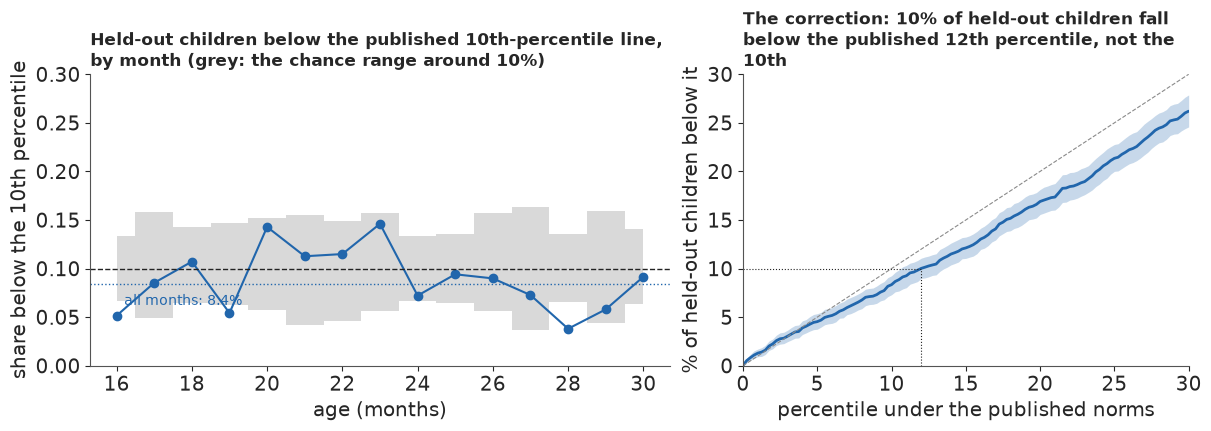

In [28]:
ers = np.random.default_rng(RANDOM_SEED)
EXAMPLES = []
for m in (18, 24, 30):
    pool = HOLD[AGE[HOLD] == m]
    for q in (0.10, 0.60):
        target = 50 if (m, q) == (24, 0.10) else np.quantile(W[pool], q)
        cand = pool[np.abs(W[pool] - target) <= max(2, 0.03 * target)]
        EXAMPLES.append(int(ers.choice(cand)))
m_hold, _ = half_estimate(np.ones(J, bool))
del prior_h
PCT_HOLD = 100 * np.array([np.interp(m_hold[k], TG, CDF[:, AGE[HOLD][k] - 16].mean(axis=0))
                           for k in range(len(HOLD))])
below_pub = np.array([np.mean(PCT_HOLD[AGE[HOLD] == m] < 10) for m in AGES])
P_PUB = np.mean(PCT_HOLD < 10)
lo1, hi1 = stats.binom.ppf([0.055, 0.945], len(HOLD), 0.1) / len(HOLD)
print("held-out children below the published 10th percentile, by month:",
      dict(zip(AGES.tolist(), below_pub.round(3).tolist())))
print(f"overall {P_PUB:.3f} below the 10th (89% chance range if the norms were right: {lo1:.3f}-"
      f"{hi1:.3f}), {np.mean(PCT_HOLD < 50):.3f} below the 50th, {np.mean(PCT_HOLD > 90):.3f} "
      "above the 90th")
print("months about their overall share:", month_spread(below_pub, P_PUB, 14))
print("months outside the 89% chance range around 10%:",
      AGES[(below_pub < lo_m) | (below_pub > hi_m)].tolist())

KEEP = ~np.isin(HOLD, EXAMPLES)                     # the correction leaves the six examples out
REF = np.sort(PCT_HOLD[KEEP])
NREF = REF.size
CAL_Y = 100 * (np.arange(NREF) + 0.5) / NREF
CAL_X = np.sort(PCT_HOLD[KEEP][np.random.default_rng(8).integers(0, NREF, (DR, NREF))], axis=1)


def calibrate(p, s=None):
    """Published percentile -> % of held-out children below it (bootstrap resample s, or all)."""
    return np.interp(p, REF if s is None else CAL_X[s], CAL_Y)


CUT_M = np.quantile(REF, 0.1)
cut_b = CAL_X[:, int(0.1 * NREF)]
CUT_24 = np.quantile(PCT_HOLD[KEEP & (AGE[HOLD] == 24)], 0.1)
print(f"published percentile below which 10% of held-out children fall: {CUT_M:.1f} (89% over "
      f"bootstrap resamples {np.quantile(cut_b, 0.055):.1f}-{np.quantile(cut_b, 0.945):.1f}); "
      f"from the {np.sum(KEEP & (AGE[HOLD] == 24))} two-year-olds alone: {CUT_24:.1f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2), width_ratios=[1.3, 1])
ax1.fill_between(AGES, lo_m, hi_m, color=LIGHT, step="mid", lw=0)
ax1.plot(AGES, below_pub, "o-", color=HI)
ax1.axhline(0.1, color=INK, lw=1, ls="--")
ax1.axhline(P_PUB, color=HI, lw=1, ls=":")
ax1.text(16.2, P_PUB - 0.01, f"all months: {P_PUB:.1%}", color=HI, fontsize=10, va="top")
ax1.set_ylim(0, 0.3)
ax1.set_xlabel("age (months)")
ax1.set_ylabel("share below the 10th percentile")
ax1.set_title(wrap("Held-out children below the published 10th-percentile line, by month (grey: "
                   "the chance range around 10%)", 60), loc="left", fontsize=12.5)
pg_ = np.linspace(0, 30, 121)
cb_ = np.array([calibrate(pg_, s) for s in range(DR)])
ax2.fill_between(pg_, *np.quantile(cb_, [0.055, 0.945], axis=0), color=HI, alpha=0.25, lw=0)
ax2.plot(pg_, calibrate(pg_), color=HI, lw=2)
ax2.plot([0, 30], [0, 30], color=MUTED, lw=0.8, ls="--")
ax2.plot([CUT_M, CUT_M, 0], [0, 10, 10], color=INK, lw=0.8, ls=":")
ax2.set_xlim(0, 30)
ax2.set_ylim(0, 30)
ax2.set_xlabel("percentile under the published norms")
ax2.set_ylabel("% of held-out children below it")
ax2.set_title(wrap(f"The correction: 10% of held-out children fall below the published "
                   f"{ordinal(CUT_M)} percentile, not the 10th", 45), loc="left", fontsize=12.5);

Against the published norms, 8.4% of held-out children fall below the 10th percentile, outside the
8.9-11.2% chance range, and 6.6% above the 90th: the tails are too heavy, as in part D, so a child
in the low tail is ranked a little too high. By month the share runs from 4% (28 months) to 15%
(23), but that spread is mostly what 55 to 194 children a month give by chance (chi-square 23 on
14 df about the overall share, p = 0.07); only 16, 19 and 28 months fall outside the band around
10%, and the two-year-olds' 7% is inside theirs.

The fix is an empirical correction of the percentile scale, as one recalibrates a forecast with
its own probability integral transform: in place of a published percentile $p$, report the share
of held-out children whose published percentile is below $p$ (right panel). The lowest 10% then
ends at the published 12th percentile (10.6-13.6 across bootstrap resamples). The correction
pools all months, since the monthly spread is mostly noise; the 192 two-year-olds alone would put
the line at the 15th, noisier but in the same direction. Each paired draw gets its own bootstrap
resample, so the correction's uncertainty travels into the percentiles.

### One child's percentile

For each of the 200 paired draws we compute the example child's posterior for $\theta$ from its
680 answers (tempered, on a 0.005 grid, with its own covariates in the prior), draw 20 abilities
from it, read off their ranks in the smooth population at the child's age, and pass each rank
through that draw's correction: 4,000 percentiles per child, carrying measurement, the norms and
the correction. Setting the ability to its posterior mean in each draw leaves only the last two.
The chance of the lowest 10% is computed exactly on the grid rather than counted from draws.

In [29]:
CT = np.empty((DR, TGF.size), dtype=np.float64)
for s in range(DR):
    CT[s] = special.log_expit(-a_d[s][None, :] * (TGF[:, None] - b_d[s][None, :])).sum(axis=1)
crng = np.random.default_rng(3)


KD = 20                                       # abilities per paired draw: 4,000 percentiles a child


def percentile_draws(i, params_only=False, temper=None, cal=True, cut=None):
    """Per paired draw: the child's ability given its answers (likelihood tempered by 1/R^2 unless
    `temper` is given), its rank at its age (0-100), corrected against the held-out children with
    that draw's bootstrap resample (unless cal=False). With `cut`: exact P(rank < cut) per draw."""
    temper = 1 / r_ld(W[i]) ** 2 if temper is None else temper
    yi = Y[i].astype(float)
    Xi, ei = design(np.array([i]))
    out, below = [], np.full(DR, np.nan)
    for s in range(DR):
        mu, scale, al = norm_params(Xi, ei, AGE[i], s)
        lp = (temper * (TGF * (yi @ a_d[s]) - yi @ (a_d[s] * b_d[s]) + CT[s])
              + sn_logpdf(TGF, mu[0], scale[0], al[0]))
        w = np.exp(lp - lp.max())
        w /= w.sum()
        rank = 100 * np.interp(TGF, TG, CDF[s, AGE[i] - 16])     # the rank of every grid ability
        if cal:
            rank = calibrate(rank, s)
        if params_only:
            out.append(np.interp([w @ TGF], TGF, rank))
        else:
            t = crng.choice(TGF, size=KD, p=w) + crng.uniform(-0.0025, 0.0025, KD)
            out.append(np.interp(t, TGF, rank))
        if cut is not None:
            below[s] = w[rank < cut].sum()
    return np.concatenate(out), below


PCT, rows = {}, []


def width(v):
    return round(np.diff(np.quantile(v, [0.055, 0.945]))[0], 1)


for i in EXAMPLES:
    pc, p_below = percentile_draws(i, cut=10)
    pp_ = percentile_draws(i, params_only=True)[0]
    pind = percentile_draws(i, temper=1.0)[0]
    pmod = percentile_draws(i, cal=False)[0]
    PCT[i] = pc
    if i == EXAMPLES[2]:
        P_DRAWS = p_below
    q20 = np.quantile(pc, (np.arange(20) + 0.5) / 20)
    same = FULL[AGE[FULL] == AGE[i]]
    rows.append(dict(age=AGE[i], words=W[i], dots=f"{q20.min():.0f}-{q20.max():.0f}",
                     median=round(np.median(pc)), uncorrected=round(np.median(pmod)),
                     raw_rank=round(100 * np.mean(W[same] < W[i])), width=width(pc),
                     width_if_independent=width(pind), width_without_measurement=width(pp_)))
EXT = pd.DataFrame(rows)
print(EXT.to_string(index=False))
i24 = EXAMPLES[2]
P_CLAIM, P_MCSE = P_DRAWS.mean(), P_DRAWS.std() / np.sqrt(DR)
P_MODEL = percentile_draws(i24, cal=False, cut=10)[1].mean()
P_24 = percentile_draws(i24, cal=False, cut=CUT_24)[1].mean()
print(f"P(lowest 10%) for the {W[i24]}-word two-year-old: {P_CLAIM:.3f} (Monte Carlo error "
      f"{P_MCSE:.3f}; middle 89% across draws {np.quantile(P_DRAWS, 0.055):.2f}-"
      f"{np.quantile(P_DRAWS, 0.945):.2f}); without the correction {P_MODEL:.3f}; with the line "
      f"set from the two-year-olds alone {P_24:.3f}")
print(f"share of Wordbank two-year-olds saying {W[i24]} words or fewer: "
      f"{np.mean(W[FULL[AGE[FULL] == 24]] <= W[i24]):.3f}")

 age  words  dots  median  uncorrected  raw_rank  width  width_if_independent  width_without_measurement
  18      9  2-19       8           10         9   13.8                   8.2                        2.3
  18     75 46-68      57           58        59   17.9                  12.0                        5.0
  24     50  6-14      10           12        10    6.1                   4.2                        2.3
  24    329 50-71      60           60        61   17.3                   8.3                        5.4
  30    131  6-12       9           11        13    4.7                   3.2                        2.6
  30    559 50-70      59           59        65   16.2                  10.3                        7.1
P(lowest 10%) for the 50-word two-year-old: 0.551 (Monte Carlo error 0.012; middle 89% across draws 0.29-0.81); without the correction 0.212; with the line set from the two-year-olds alone 0.912
share of Wordbank two-year-olds saying 50 words or fewer: 0.105


The two-year-old with 50 words lands between the 6th and 14th percentile: those are the ends of
its 20 equally likely answers (median 10th, the same as its raw rank among Wordbank
two-year-olds). Without the correction its median would be the 12th. Its 89% range is 6 points
wide; with independent words it would have been 4, and without measurement error 2.3. The chance
that it is in the lowest 10% is 55%, with a Monte Carlo error of about 1 point; across draws of
the norms and the correction it ranges from 29% to 81%, so the correction is the largest source of
doubt in this number. Uncorrected, the model would have said 21%.

The dots describe the child's underlying ability: what this checklist implies about the child's
usual vocabulary, as it might show on another day or another form. Today's count has a rank of its
own, with no measurement width: 10.5% of Wordbank's two-year-olds say 50 words or fewer, so on
this form, today, the child is at the 10th percentile.

The width in percentile points depends on how precisely the checklist measures the child (worst
at the floor and the ceiling, and the section effect weighs more above 100 words) and on how
crowded the population is at the child's place: a given error in ability crosses more points
where children are bunched, near the middle, than in the thin lower tail. So the low children at
24 and 30 months are placed within 5-6 points, the 9-word 18-month-old at the floor within about
14, and the children near the 60th percentile within 16-18, of which the correction and the norms
account for 5-7. The 30-month-old with 559 words sits at the 59th percentile against a raw rank of
65: Wordbank's own 30-month-olds are a little behind the smooth curve (month deviation -0.11).

The statistician's summary of the same facts is the **test information** curve, $I(\theta) =
\sum_j a_j^2 p_j(\theta)(1 - p_j(\theta))$, whose inverse square root is the standard error of an
ability estimate.

24-month example: theta -1.332 (posterior sd 0.064, 0.101 allowing for sections); point percentile 11.6 (9.7 after the correction)


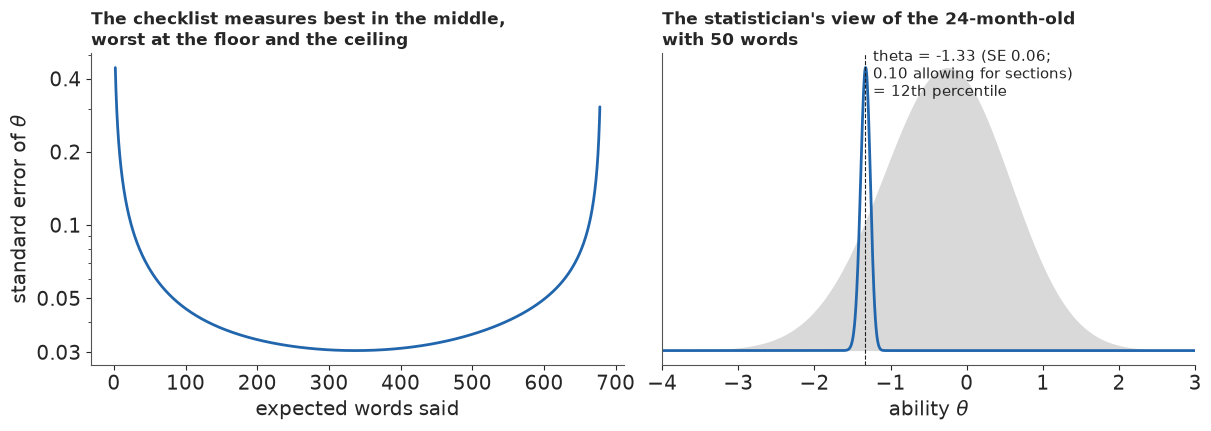

In [30]:
INFO = (A_M[None, :] ** 2 * special.expit(A_M * (TG[:, None] - B_M)) *
        special.expit(-A_M * (TG[:, None] - B_M))).sum(axis=1)
EW_M = special.expit(A_M * (TG[:, None] - B_M)).sum(axis=1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))
keep = (EW_M > 2) & (EW_M < 678)
ax1.plot(EW_M[keep], 1 / np.sqrt(INFO[keep]), color=HI, lw=2)
ax1.set_xlabel("expected words said")
ax1.set_ylabel(r"standard error of $\theta$")
ax1.set_yscale("log")
ax1.set_yticks([0.03, 0.05, 0.1, 0.2, 0.4], ["0.03", "0.05", "0.1", "0.2", "0.4"])
ax1.yaxis.set_minor_formatter(plt.NullFormatter())
ax1.set_title("The checklist measures best in the middle,\nworst at the floor and the ceiling",
              loc="left", fontsize=12.5)
yi = Y[i24].astype(float)
lpost = TGF * (yi @ A_M) - yi @ (A_M * B_M) + C_M
Xi, ei = design(np.array([i24]))
mu_i = NM["f"].mean(axis=0)[8] + Xi @ NM["beta"].mean(axis=0) + NM["b_edu"].mean() * ei
lpost = lpost + sn_logpdf(TGF, mu_i[0], 1.0, al_m[0])
post = np.exp(lpost - lpost.max())
dens24 = DENS[:, 8].mean(axis=0)
ax2.fill_between(TG, dens24 / dens24.max(), color=LIGHT, lw=0)
ax2.plot(TGF, post / post.max(), color=HI, lw=2)
th_mean = (post @ TGF) / post.sum()
th_sd = np.sqrt((post @ TGF**2) / post.sum() - th_mean**2)
p_pt = 100 * np.interp(th_mean, TG, CDF[:, 8].mean(axis=0))
ax2.axvline(th_mean, color=INK, lw=0.8, ls="--")
ax2.text(th_mean + 0.1, 0.9,
         f"theta = {th_mean:.2f} (SE {th_sd:.2f};\n{r_ld(W[i24]) * th_sd:.2f} allowing for "
         f"sections)\n= {ordinal(p_pt)} percentile",
         fontsize=10.5)
ax2.set_xlim(-4, 3)
ax2.set_xlabel(r"ability $\theta$")
ax2.set_yticks([])
ax2.set_title(f"The statistician's view of the 24-month-old\nwith {W[i24]} words", loc="left",
              fontsize=12.5)
print(f"24-month example: theta {th_mean:.3f} (posterior sd {th_sd:.3f}, "
      f"{r_ld(W[i24]) * th_sd:.3f} allowing for sections); point percentile {p_pt:.1f} "
      f"({float(calibrate(p_pt)):.1f} after the correction)")

If the words were independent, the checklist would measure ability to about 0.03 units between 150
and 550 words, but only to about 0.1 below 30 words and 0.4 at the floor: the form has few words
that a child with ten words is on the verge of saying. Failure 5 multiplies these by 1.6 to 3.0.
On the right is the report a psychometrician would write for the 24-month-old: an ability of -1.33
with a standard error of 0.06 (0.10 allowing for sections), a density far narrower than the
population's, and a single percentile, the 12th on the published scale (the 10th after the
correction).

## H · Explaining it to everyone

### The statistician's plot, and what a parent needs

The two panels above are correct and nearly useless to a parent: a latent scale means nothing
outside the model, and a single percentile sounds more exact than it is.

### "You are here"

The public display shows the percentile as 20 equally likely answers, a **quantile dotplot**, so
a reader can count the dots below any line. People read probabilities from quantile dotplots more
consistently than from densities (Kay, Kola, Hullman & Munson, CHI 2016), and 20-dot plots led to
better decisions than text (Fernandes et al., CHI 2018); there is no line at the middle, which
invites readers to ignore the spread (Kale, Kay & Hullman 2021, *IEEE TVCG*). Above the dots a
**graded fan** of words by age, corrected like the dots, puts the child on a growth chart, with
shades and no hard edge as in the Bank of England's fan charts (Britton, Fisher & Whitley 1998;
Spiegelhalter, Pearson & Short 2011). A 0-100 bar locates the enlarged window, and the lowest 10%
carries a plain label: where screening looks closer, not a diagnosis. The figure is the one at
the top of the notebook.

corrected fan at 24 months (10/25/75/90%): [ 54. 127. 425. 532.]  data: [ 50.   120.25 427.75 531.5 ]


A two-year-old who says 50 words is around the 10th percentile, somewhere between the 6th and the 14th: 11 of 20 dots fall in the lowest 10%
P(percentile < 10) for the 24-month example: 0.551 (Monte Carlo error 0.012); dots below 10: 11 of 20


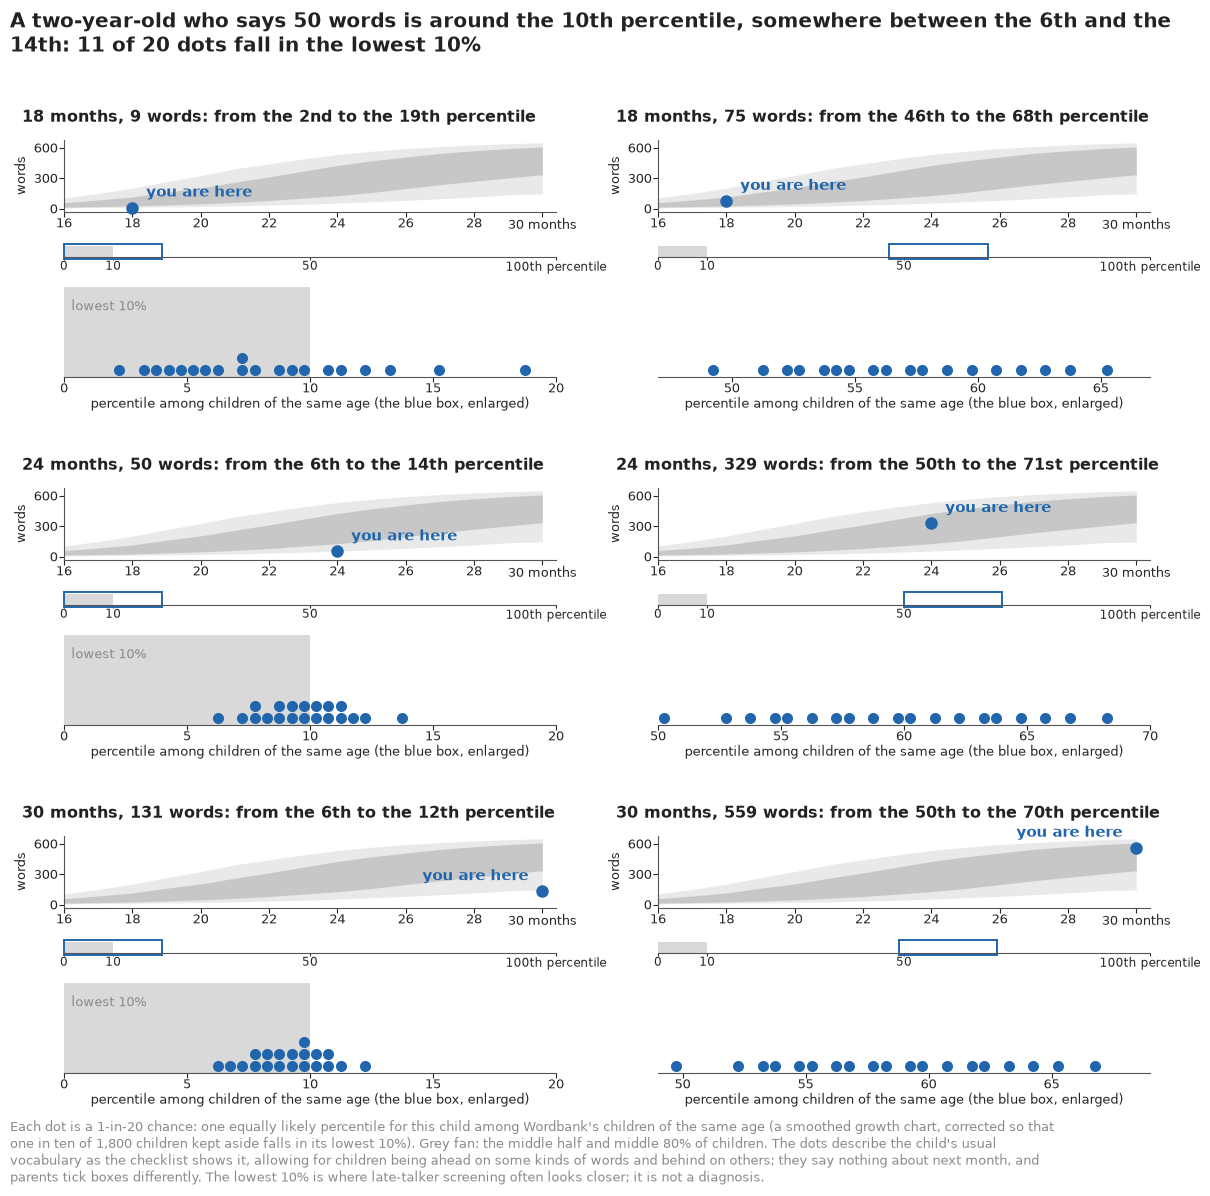

In [31]:
FAN_LV = np.quantile(REF, [0.1, 0.25, 0.75, 0.9]) / 100     # the corrected 10/25/75/90% lines
FAN = np.zeros((AGES.size, len(FAN_LV)))
frng = np.random.default_rng(4)
for i in range(AGES.size):
    sims = []
    for s in range(DR):
        t = np.interp(frng.uniform(size=100), CDF[s, i], TG)
        sims.append(frng.normal(np.interp(t, TG, EW[s]), np.sqrt(np.interp(t, TG, VW[s]))))
    FAN[i] = np.quantile(np.clip(np.concatenate(sims), 0, J), FAN_LV)
print("corrected fan at 24 months (10/25/75/90%):", FAN[8].round(0), " data:", QW[8, [0, 1, 3, 4]])

PC24 = PCT[EXAMPLES[2]]
CUT = 10                                 # the lowest-10% line used throughout (part A onwards)
q24 = np.quantile(PC24, (np.arange(20) + 0.5) / 20)
HEAD_TITLE = (f"A two-year-old who says {W[EXAMPLES[2]]} words is around the "
              f"{ordinal(np.median(PC24))} percentile, somewhere between the "
              f"{ordinal(q24.min())} and the {ordinal(q24.max())}: "
              f"{(q24 < CUT).sum()} of 20 dots fall in the lowest 10%")


SPAN = 20                                                 # percentile points in a zoom window


def dot_layout(pc, lo_w, bw, n=20):
    """Quantile dots in columns of width bw: x centres and stack heights (in units of bw)."""
    q = np.quantile(pc, (np.arange(n) + 0.5) / n)
    col = np.floor((q - lo_w) / bw + 1e-9).astype(int)
    k = np.array([np.sum(col[:j] == col[j]) for j in range(n)])
    return lo_w + (col + 0.5) * bw, k


def window(pc):
    return float(np.clip(np.round(np.median(pc) - SPAN / 2), 0, 100 - SPAN)) + 0.0   # no "-0"


def you_are_here(fig, box, i, bw):
    """A panel: fan of words by age with the child marked, a 0-100 locator, a zoomed 20-dot plot.

    Local helper: pub.quantile_dotplot forces an equal aspect, which resizes fixed panels, so here
    the dot size is computed from the axes size instead (dots stay round and equal everywhere)."""
    x0, y0, w0, h0 = box
    pc = PCT[i]
    q = np.quantile(pc, (np.arange(20) + 0.5) / 20)
    fig.text(x0, y0 + h0, f"{AGE[i]} months, {W[i]} words: from the {ordinal(q.min())} to the "
             f"{ordinal(q.max())} percentile", fontsize=11.5, va="top", color=INK, weight="bold")
    ax1 = fig.add_axes([x0 + 0.035, y0 + 0.66 * h0, w0 - 0.035, 0.24 * h0])
    for (lo_, hi_), al in (((0, 3), 0.18), ((1, 2), 0.35)):
        ax1.fill_between(AGES, FAN[:, lo_], FAN[:, hi_], color=MUTED, alpha=al, lw=0)
    ax1.plot(AGE[i], W[i], "o", color=HI, ms=8, zorder=5, clip_on=False)
    right = AGE[i] > 26
    ax1.annotate("you are here", (AGE[i], W[i]), xytext=(-10 if right else 10, 8),
                 textcoords="offset points", ha="right" if right else "left", fontsize=11,
                 color=HI, weight="bold")
    ax1.set_xlim(16, 30.4)
    ax1.set_ylim(-30, J)
    ax1.set_yticks([0, 300, 600])
    ax1.set_xticks([16, 18, 20, 22, 24, 26, 28, 30], ["16", "18", "20", "22", "24", "26", "28",
                                                      "30 months"])
    ax1.tick_params(labelsize=9, pad=1)
    ax1.set_ylabel("words", fontsize=9.5)
    lo_w = window(pc)
    ax2 = fig.add_axes([x0 + 0.035, y0 + 0.51 * h0, w0 - 0.035, 0.035 * h0])
    ax2.add_patch(Rectangle((0, 0), 10, 1, color=LIGHT, lw=0))
    ax2.add_patch(Rectangle((lo_w, -0.2), SPAN, 1.4, fc="none", ec=HI, lw=1.4, clip_on=False))
    ax2.set_xlim(0, 100)
    ax2.set_ylim(0, 1)
    ax2.set_yticks([])
    ax2.set_xticks([0, 10, 50, 100], ["0", "10", "50", "100th percentile"], fontsize=8.5)
    ax2.tick_params(length=2, pad=1)
    for sp in ("left", "right", "top"):
        ax2.spines[sp].set_visible(False)
    ax3 = fig.add_axes([x0 + 0.035, y0 + 0.11 * h0, w0 - 0.035, 0.30 * h0])
    wpt = ax3.get_position().width * fig.get_figwidth() * 72
    hpt = ax3.get_position().height * fig.get_figheight() * 72
    yspan = SPAN * hpt / wpt                                          # data units with equal scale
    if lo_w < 10:
        ax3.axvspan(lo_w, 10, color=LIGHT, lw=0, zorder=0)
        ax3.text(lo_w + 0.3, yspan * 0.86, "lowest 10%", fontsize=9, color=MUTED, va="top")
    xs, k = dot_layout(pc, lo_w, bw)
    ax3.scatter(xs, (k + 0.5) * bw, s=(0.9 * bw * wpt / SPAN) ** 2, color=HI, lw=0, zorder=3)
    ax3.set_xlim(lo_w, lo_w + SPAN)
    ax3.set_xticks(np.arange(np.ceil(lo_w / 5) * 5, lo_w + SPAN + 0.1, 5))
    ax3.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0f}"))
    ax3.set_ylim(0, yspan)
    ax3.set_yticks([])
    for sp in ("left", "right", "top"):
        ax3.spines[sp].set_visible(False)
    ax3.tick_params(labelsize=9, pad=1)
    ax3.set_xlabel("percentile among children of the same age (the blue box, enlarged)",
                   fontsize=9.5, labelpad=1)


def common_bw(yspan):
    """The widest dot column (1, 1/2 or 1/4 point) at which every panel's stacks fit in yspan."""
    for bw in (1.0, 0.5, 0.25):
        if all((dot_layout(PCT[i], window(PCT[i]), bw)[1].max() + 1) * bw <= yspan
               for i in EXAMPLES):
            return bw
    return 0.25


def headline_figure():
    fig = plt.figure(figsize=(12, 12), layout="none")
    fig.text(0.02, 0.988, wrap(HEAD_TITLE, 100), fontsize=14.5, weight="bold", va="top", color=INK)
    bw = common_bw(SPAN * (0.30 * 0.25 * 12) / ((0.445 - 0.035) * 12))
    for k, i in enumerate(EXAMPLES):
        r, c = divmod(k, 2)
        you_are_here(fig, (0.03 + 0.495 * c, 0.075 + (2 - r) * 0.29, 0.445, 0.25), i, bw)
    fig.text(0.02, 0.008, wrap(
        "Each dot is a 1-in-20 chance: one equally likely percentile for this child among "
        "Wordbank's children of the same age (a smoothed growth chart, corrected so that one in "
        "ten of 1,800 children kept aside falls in its lowest 10%). Grey fan: the middle half and "
        "middle 80% of children. The dots describe the child's usual vocabulary as the checklist "
        "shows it, "
        "allowing for children being ahead on some kinds of words and behind on others; they say "
        "nothing about next month, and parents tick boxes differently. The lowest 10% is where "
        "late-talker screening often looks closer; it is not a diagnosis.", 160),
        fontsize=9.5, color=MUTED, va="bottom")
    return fig


fig_top = headline_figure()
HEADLINE.update(fig_top)
plt.close(fig_top)
headline_figure()
print(HEAD_TITLE)
print(f"P(percentile < {CUT}) for the 24-month example: {P_CLAIM:.3f} (Monte Carlo error "
      f"{P_MCSE:.3f}); dots below {CUT}: {(q24 < CUT).sum()} of 20")

Six children, six statements a parent can read: the 24-month-old with 50 words is somewhere
between the 6th and 14th percentile, the 18-month-old with 9 words between the 2nd and the 19th,
the 30-month-old with 131 words between the 6th and 12th. Eleven of the 50-word child's 20 dots
lie in the lowest 10%. With the correction, the fan at 24 months (10th to 90th percentile about
54 to 530 words) matches the raw one (50 to 530). For the summary we turn the 24-month panel into
one probability.

In [32]:
SURE = pub.how_sure(
    P_CLAIM, f"this {W[i24]}-word two-year-old is among the lowest 10% of Wordbank's "
    "two-year-olds", "medium",
    f"the model alone said {P_MODEL:.0%}, but its lowest-10% line held only {P_PUB:.1%} of "
    "1,800 children kept aside, so we corrected it with those children; a checklist is one "
    "parent's report on one day; and Wordbank's families are research volunteers, not a random "
    "sample")
print(SURE)
HOW_SURE.update(Markdown("**How sure are we.** " + SURE))

It is *about as likely as not* (55%) that this 50-word two-year-old is among the lowest 10% of Wordbank's two-year-olds. We have *medium confidence* in that figure: the model alone said 21%, but its lowest-10% line held only 8.4% of 1,800 children kept aside, so we corrected it with those children; a checklist is one parent's report on one day; and Wordbank's families are research volunteers, not a random sample.


The line is the lowest 10%, the late-talker line used since part A; an earlier draft used the
15th percentile, and we moved to the 10th after seeing results, for consistency. The direction of
the correction is clear, its size less so: across draws the probability runs from 29% to 81%, and
a line set from the 192 two-year-olds alone would give 91%. "About as likely as not" is the honest
word; the uncorrected model's "unlikely" (21%) would not be.

### A first-words ladder

Which words come first gets a **ladder** of familiar words ordered by age of acquisition, each a
**gradient interval** (darker where more plausible) rather than an error bar, whose ends readers
treat as hard limits (Correll & Gleicher 2014, *IEEE TVCG*). Beside each word, a natural
frequency out of 100 two-year-olds (Akl et al. 2011). Words common before 16 months, and those
that wait past 30, go in the title, since the window cannot place them.

{'car': '17.6', 'eye': '17.7', 'nose': '18.0', 'cat': '18.2', 'duck': '18.2', 'apple': '18.3', 'cookie': '18.6', 'bath': '18.7', 'hat': '19.1', 'juice': '19.3', 'truck': '19.6', 'cup': '19.8', 'spoon': '20.6', 'bed': '20.9', 'happy': '23.5', 'later': '28.6'}
{'mommy*': '0.96 (data 0.96)', 'ball': '0.95 (data 0.95)', 'dog': '0.90 (data 0.88)', 'because': '0.15 (data 0.10)'}


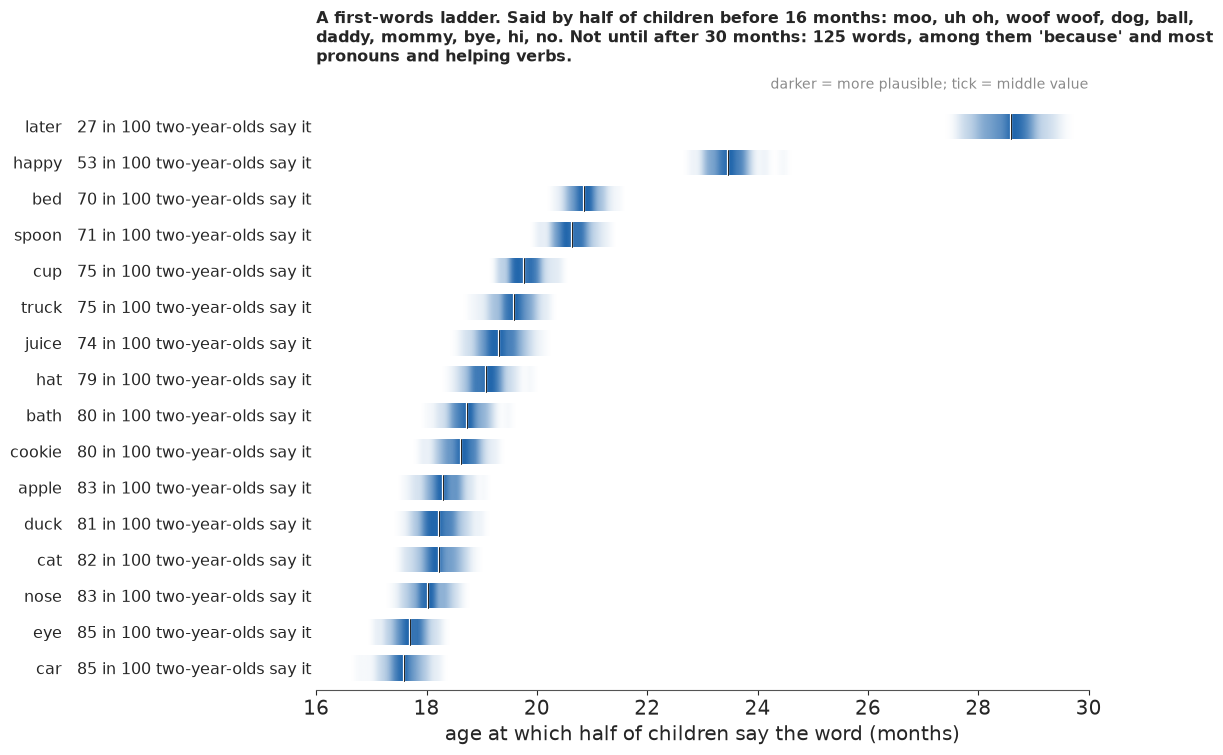

In [33]:
LADDER = ["car", "eye", "cat", "shoe", "duck", "nose", "juice", "cookie", "bath",
          "apple", "hat", "bed", "cup", "spoon", "truck", "happy", "tomorrow", "why", "later"]
LADDER = sorted([w_ for w_ in LADDER if fin[wid(w_)]], key=lambda w_: AOA_MED[wid(w_)])
P24 = P_REF[:, 8]
names = []
for w_ in LADDER:
    lo_, mid_, hi_ = pub.freq_range(P24[:, wid(w_)], 100)
    names.append(f"{w_}   {mid_} in 100 two-year-olds say it")
fig, ax = plt.subplots(figsize=(11, 0.34 * len(LADDER) + 2.0))
pub.gradient_intervals(ax, [AOA[:, wid(w_)] for w_ in LADDER][::-1], names[::-1], xlim=(16, 30),
                       xlabel="age at which half of children say the word (months)")
early_words = ", ".join(w.rstrip("*") for w in WORDS[early])
ax.set_title(wrap("A first-words ladder. Said by half of children before 16 months: "
                  f"{early_words}. "
                  f"Not until after 30 months: {late.sum()} words, among them 'because' and most "
                  "pronouns and helping verbs.", 100), loc="left", fontsize=11.5, pad=22)
print({w_: f"{AOA_MED[wid(w_)]:.1f}" for w_ in LADDER})
print({w_: f"{P24[:, wid(w_)].mean():.2f} (data {EMP[8, wid(w_)]:.2f})" for w_ in
       ("mommy*", "ball", "dog", "because")})

The ladder runs from car, eye and nose (17.6-18 months) through truck and cup near 20 to happy at
23.5 and later at about 28.5. The fractions are the other side of the coin: 85 in 100
two-year-olds say "car", 53 "happy", 27 "later". The model's fractions for the earliest words
match the raw ones (96 in 100 for mommy in both, 95 for ball); for "because" it says 15 against 10
in the data, its usual excess at the top of the curve.

### Girls and boys, in words and numbers

For the group question we use a **calibrated-language strip**: the IPCC's scale of likelihood
words (Mastrandrea et al. 2010) with the probability marked on it, because readers interpret words
like "likely" far more variously than their numbers, and a word plus a number narrows the gap
(Budescu, Broomell & Por 2009), while numeric uncertainty costs little trust (van der Bles et al.
2020, *PNAS*).

P(girls say more at 24 months): 1.000 of 200 draws; the gap is 8.0 sds above 0, so about 1 - 8e-16 under a normal approximation


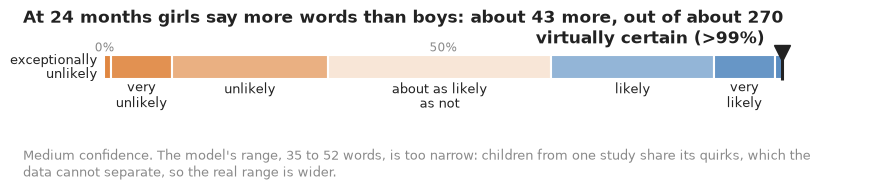

In [34]:
G24 = GAPS["girls - boys, 24 months"]
Z_GIRL = G24.mean() / G24.std()
P_GIRL = stats.norm.cdf(Z_GIRL)                # 200 draws alone cannot show more than about 98.5%
g24 = np.quantile(G24, [0.055, 0.5, 0.945])
fig, ax = plt.subplots(figsize=(10, 2.3), layout="none")
fig.subplots_adjust(left=0.08, right=0.92, top=0.66, bottom=0.36)
pub.word_strip(ax, P_GIRL, f"At 24 months girls say more words than boys: about {g24[1]:.0f} "
               "more, out of about 270")
for t_ in list(ax.texts):                      # keep the pointer's label clear of the pointer
    if t_.get_text().startswith(pub.calibrated_word(P_GIRL) + " ("):
        t_.set_x(P_GIRL - 0.025)
        t_.set_horizontalalignment("right")
    elif t_.get_text() == pub.calibrated_word(P_GIRL).replace(" ", "\n"):
        t_.remove()                            # the end band is named by the pointer's label
fig.text(0.08, 0.02, wrap(f"Medium confidence. The model's range, {g24[0]:.0f} to {g24[2]:.0f} "
                          "words, is too narrow: children from one study share its quirks, which "
                          "the data cannot separate, so the real range is wider.", 120),
         fontsize=9.5, color=MUTED, va="bottom")
print(f"P(girls say more at 24 months): {np.mean(G24 > 0):.3f} of {DR} draws; the gap is "
      f"{Z_GIRL:.1f} sds above 0, so about 1 - {stats.norm.sf(Z_GIRL):.0e} under a normal "
      "approximation")

"Virtually certain (>99%)" is a probability under the model: the gap sits 8 sds above zero (200
draws alone could not show more than about 98.5%, so we use a normal approximation). The doubt
about the model belongs in the confidence statement, in the caption. The direction of the gap
would survive much wider intervals; its size, about 43 words, is the part to hold loosely.

### What the public version gains, and what it costs

The dotplot answers the parent's question in the parent's terms: a percentile among children of
the same age, with an honest width, on a growth chart. The statistician's plot shows more, such
as that the checklist is least precise for children who say almost nothing, like the 9-word
18-month-old; the public version shows that only through the spread of the dots. Three pitfalls
go wherever the figure goes. The dots measure what this checklist says; they
leave out how differently parents tick boxes, week-to-week change and the study mix, any of which
may be larger than the dots' width. The norms are Wordbank's families, whose caregivers are far
more educated than the country's, so a child of a secondary-educated caregiver is compared with
children who are, on average, ahead. And a shaded "lowest 10%" invites a verdict; the caption says
what it is. A zoomed dotplot can also make 7 points look wide, which is what the 0-100 bar is for.

In [35]:
TIMES["total"] = time.time() - T_START
print({k: round(v) for k, v in TIMES.items()})

{'tiny': 10, 'map': 14, 'stage1': 57, 'stage2_monotone': 63, 'stage2': 24, 'cells': 6, 'dif': 6, 'total': 213}


## Summary

- **A 680-word checklist reduces to two numbers per child.** Under a 2PL each child's ability is
  integrated out in one dimension: 680 words calibrate on 900 children in a minute (0 divergences,
  r_hat at most 1.012); a parameter per child did not finish in 25 minutes for 600 children.
- **Adaptive quadrature finds needle-thin posteriors** that a 0.1 grid misses (15.5 nats off,
  against 0.12 for eight adaptive nodes at the mode and 3.5-5.3 at posterior draws).
- **The scale has to be defined.** Free section means let the chains drift along an exact ridge
  (r_hat 1.43, zero divergences); a zero-sum constraint fixed it.
- **Counting by cells is 14 times too sure**: the same girl shift, a fourteenth of the width.
- **Wordbank's months are different samples.** A monotone growth curve stalled after an advanced
  28th month; a smooth curve with orthogonal month deviations fixed it. Unidentified studies
  remain the main limit.
- **First words.** Ten words come before 16 months (mommy, daddy, ball, dog ...), about 125 after
  30; the model's ages match the raw curves (correlation 0.985).
- **Group gaps are real and modest.** At 24 months girls say about 43 more words than boys
  (35-52), first-borns about 31 more, children of graduates about 53 more than of
  secondary-educated caregivers; the intervals ignore study clustering and are too narrow.
- **Eighteen words are biased**, learned about 2-5 months earlier by one sex at the same
  vocabulary (6-8 for the two anatomical words), such as doll and dress for girls, truck and
  vroom for boys.
- **The words are not independent.** Section-split half-forms disagree 1.6-3.0 times as much as
  a within-section split; tempering widens percentile ranges 1.5-2.1 times, a rough correction
  chosen after the check (a testlet model is the proper one).
- **The published percentiles needed a correction.** 8.4% of 1,800 held-out children fell below
  the 10th-percentile line, outside the chance range; monthly swings were mostly noise. Corrected,
  the lowest 10% ends at the published 12th (10.6-13.6).
- **For one child** the width depends on measurement precision and how crowded the population is
  at the child's place: 5-6 points for the low examples, 16-18 near the 60th. A two-year-old with
  50 words is around the 10th percentile (6th-14th), *about as likely as not* (55%) in the lowest
  10%, with medium confidence: uncorrected the model said 21%, a correction from two-year-olds
  alone would say 91%.
- **For the public**: a "you are here" quantile dotplot under a graded fan, a first-words
  ladder of gradient intervals with natural frequencies, and a calibrated-language strip, against
  the test information curve and a single percentile.

## Try it yourself

1. **A short form.** Choose the 25 words most informative near the 10th percentile at 24 months
   and recompute the 24-month examples' dots from them. Is a short form good enough to screen?
2. **Item bias for birth order.** Repeat the two-step horseshoe for first-born against later-born
   children. Which words, if any, do older siblings bring in early?
3. **Norms for the country.** Reweight the reference mix to the education shares of American
   parents of young children instead of Wordbank's, and recompute the 50-word two-year-old's
   percentile. How much of "the 10th percentile" is a statement about who volunteers for studies?